# How big is the fBVOC prescription artefact in PD, and does it depend on the land cover?

**Why this notebook.** Prescribing the BVOC emissions (MEGAN off, 2001–2014 climatology) raises SOA by about +3 % by itself (`fbvoc_prescription_artefact.ipynb`). The replay test traced this to using a **climatology** (`fbvoc_artefact_causes.ipynb`, H5). The BVOC effect is therefore measured with a **matched baseline** (design B, user 2026-10-30). Its one extra assumption is tested here with a short run, **LCC_PD_fBVOClccPD** (LCC land, its own LCC_PD emissions prescribed, 2000–2002; script `cases-scripts/14e-…`).

**Notation.** `art(land)` = run with interactive MEGAN − the same run with its own emissions prescribed (sign convention: interactive − prescribed, user 2026-11-07; before that date the opposite sign was used, so older outputs and logs show art and δ flipped).

| Key | Contrast | What it measures |
|---|---|---|
| **art_CTRL** | CTRL_PD − CTRL_PD_fBVOCctrlPD | artefact on CTRL land |
| **art_LCC** | LCC_PD − LCC_PD_fBVOClccPD | artefact on LCC land |
| **δ_PD** | art_LCC − art_CTRL | **how much the artefact depends on the land cover** |
| **BVOC_B** | (LCC_PD − LCC_PD_fBVOCctrlPD) − art_CTRL | PD BVOC effect, design B (matched baseline) |
| **BVOC_A** | LCC_PD_fBVOClccPD − LCC_PD_fBVOCctrlPD | PD BVOC effect, design A (prescribed pair) |
| **C** | LCC_PD − LCC_PD_fBVOCctrlPD | uncorrected `BVOC_PD` (for reference) |

**Key identity.** BVOC_B − BVOC_A = δ_PD (exact for absolute changes, first order for % changes). Design B is right if δ_PD is small compared with BVOC_B.

**How to read it (decision rule, proposed; SOA_cb, Global and 45–90°N):**

- R = |δ_PD| / |BVOC_B|.
- **R < 0.25** → B is adequate; no design-A runs for FUT.
- **R > 0.5** → the artefact depends on the land; design A in FUT is worth its 2 runs (LCC_FUT rerun with HR_BVOC_ALL + LCC_FUT_fBVOClccFUT).
- **In between** → judgement, look at the bands and years.

**Caveats.**

- Only 2 comparison years (2001–2002; 2000 dropped as spin-up). All 5 runs are nudged to the same winds and pressure, so most weather noise cancels in δ (b).
- The climatology ≠ the actual 2001–2002 emissions. That part appears in both art_LCC and art_CTRL and should cancel in δ (b).
- δ_PD from 2001–2002 is assumed to hold for 2001–2014.
- **All five runs must be from the new (CO₂-fix) chain.** The notebook checks each file's `casename` against the auto-launcher's state.

Outputs: `how_big_artefact_is_PD_outputs/` (`figures/`, `tables/`).

In [1]:
import os, sys
from pathlib import Path
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt

REPO = Path('/cluster/home/adelez/BOREAL-FOREST-EXPANSION')
sys.path.insert(0, str(REPO / 'src'))
from boreal_forest_expansion.plotting import forcing_maps as fm

PROC = fm.POSTPROCESSED_DIR
PROC_OLD = PROC / '2001-2014-all-bvoc-pre-co2-fix'   # test-mode stand-ins (e.g. CTRL_PD_fBVOCctrlPD_HR) live here
STATE = Path('/cluster/work/users/adelez/auto-launch')   # <script>.case = new-chain case names
OUT = Path(os.environ.get('ARTEFACT_PD_OUT', 'how_big_artefact_is_PD_outputs'))
for sub in ('figures', 'tables'):
    (OUT / sub).mkdir(parents=True, exist_ok=True)

# key: (alias, auto-launch script)
RUNS = {'ctrl': ('CTRL_PD', '13a'), 'lcc': ('LCC_PD', '14a'), 'ctrl_f': ('CTRL_PD_fBVOCctrlPD', '14c'),
        'lcc_fc': ('LCC_PD_fBVOCctrlPD', '14b'), 'lcc_fl': ('LCC_PD_fBVOClccPD', '14e')}
# Testing only: ARTEFACT_PD_TEST=<alias> stands in for LCC_PD_fBVOClccPD and allows old-chain files
STANDIN = os.environ.get('ARTEFACT_PD_TEST')
if STANDIN:
    RUNS['lcc_fl'] = (STANDIN, None)
    print(f'!!! TEST MODE: lcc_fl = {STANDIN}, old-chain files allowed. These numbers are NOT the result !!!')
ALIAS = {k: a for k, (a, _) in RUNS.items()}

def procdir(alias):
    # folder of the processed files of alias: the stand-in comes from the old-chain archive folder
    return PROC_OLD if STANDIN and alias == STANDIN else PROC

def span(alias, cls='SOA'):
    # (first, last) year of the processed file alias/cls; None if there is none
    f = sorted(procdir(alias).glob(f'{alias}_atm_{cls}_*-*.nc'))
    if not f:
        return None
    y0, y1 = f[0].stem.rsplit('_', 1)[1].split('-')
    return int(y0), int(y1)

rows = []
for k, (alias, script) in RUNS.items():
    sp = span(alias)
    expected = (STATE / f'{script}.case').read_text().strip() if script and (STATE / f'{script}.case').exists() else None
    found = xr.open_dataset(procdir(alias) / fm.filename(alias, 'SOA', *sp).name).attrs.get('casename') if sp else None
    ok = sp is not None and (STANDIN is not None or (expected is not None and found == expected))
    rows.append(dict(key=k, alias=alias, processed_years=sp, case_in_file=found, new_chain_case=expected, ok=ok))
STATUS = pd.DataFrame(rows).set_index('key')
READY = bool(STATUS['ok'].all())
YEARS = list(range(*(lambda s: (s[0], s[1] + 1))(span(ALIAS['lcc_fl'])))) if READY else []
if READY:
    for k in RUNS:
        y0, y1 = STATUS.loc[k, 'processed_years']
        READY &= y0 <= YEARS[0] and y1 >= YEARS[-1]
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 70)
display(STATUS)
print('READY:', READY, '| comparison years:', YEARS if READY else 'pending')
if not READY:
    print('Pending: every run must be processed and come from the new chain (case_in_file = new_chain_case).')

,alias,processed_years,case_in_file,new_chain_case,ok
key,,,,,
ctrl,CTRL_PD,"(2001, 2014)",NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20261029,NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20261029,True
lcc,LCC_PD,"(2001, 2014)",NF2000norbc_tropstratchem_nudg_lcc_f19_f19-20261028,NF2000norbc_tropstratchem_nudg_lcc_f19_f19-20261028,True
ctrl_f,CTRL_PD_fBVOCctrlPD,"(2001, 2014)",NF2000norbc_tropstratchem_nudg_ctrl_fBVOCctrlPD_f19_f19-20261031,NF2000norbc_tropstratchem_nudg_ctrl_fBVOCctrlPD_f19_f19-20261031,True
lcc_fc,LCC_PD_fBVOCctrlPD,"(2001, 2014)",NF2000norbc_tropstratchem_nudg_lcc_fBVOCctrlPD_f19_f19-20261031,NF2000norbc_tropstratchem_nudg_lcc_fBVOCctrlPD_f19_f19-20261031,True
lcc_fl,LCC_PD_fBVOClccPD,"(2001, 2014)",NF2000norbc_tropstratchem_nudg_lcc_fBVOClccPD_f19_f19-20261031,NF2000norbc_tropstratchem_nudg_lcc_fBVOClccPD_f19_f19-20261031,True


READY: True | comparison years: [2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014]


## 1. Yearly fields
Calendar-year means weighted by month length (`fm.annual_mean`). 3-D fields: lowest model level. `SOA_cb` = column burden of interstitial SOA (A1 + NA). Same variable set as `fbvoc_prescription_artefact.ipynb`.

In [2]:
def open_years(alias, cls, years):
    y0, y1 = span(alias, cls)
    ds = xr.open_dataset(procdir(alias) / fm.filename(alias, cls, y0, y1).name)
    ds = ds.isel(time=ds['time'].dt.year.isin(years).values)
    missing = sorted(set(years) - set(np.unique(ds['time'].dt.year.values)))
    if missing:
        raise ValueError(f'{alias} {cls}: years {missing} missing')
    return ds

def ym(v, lev=None, scale=1.0):
    def f(ds):
        da = ds[v] if lev is None else ds[v].isel(lev=lev)
        return fm.annual_mean(da, ds) * scale
    return f

# name: (class, yearly field, units, report relative change [%]?)
VARS = {
    'SFISOP':     ('BVOC', ym('SFISOP'), 'kg m-2 s-1', True),
    'SFMTERP':    ('BVOC', ym('SFMTERP'), 'kg m-2 s-1', True),
    'cb_ISOP':    ('BVOC', ym('cb_ISOP'), 'kg m-2', True),
    'cb_MTERP':   ('BVOC', ym('cb_MTERP'), 'kg m-2', True),
    'cb_SOA_LV':  ('SOA', ym('cb_SOA_LV'), 'kg m-2', True),
    'cb_SOA_SV':  ('SOA', ym('cb_SOA_SV'), 'kg m-2', True),
    'SOA_cb':     ('SOA', ym('SOA_cb', scale=1e6), 'mg m-2', True),
    'N_AER_sfc':  ('SOA', ym('N_AER', lev=-1), 'cm-3', True),
    'OH_sfc':     ('CHEM', ym('OH', lev=-1), 'mol mol-1', True),
    'CDNC_incld': ('CLOUDPROP', lambda ds: fm.yearly_field(ds, 'ACTNL_incld'), 'cm-3', True),
    'LWP':        ('CLOUDPROP', lambda ds: fm.yearly_field(ds, 'TGCLDLWP_gm2'), 'g m-2', True),
    'NET_toa':    ('RADIATIVE', ym('NET_toa'), 'W m-2', False),
}

def fields(alias, years):
    out, opened = {}, {}
    for name, (cls, fn, units, rel) in VARS.items():
        try:
            if cls not in opened:
                opened[cls] = open_years(alias, cls, years)
            out[name] = fn(opened[cls]).load()
        except (KeyError, TypeError, ValueError, FileNotFoundError) as e:
            print(f'  {alias}: {name} skipped ({type(e).__name__}: {e})')
    return out

if READY:
    F = {k: fields(a, YEARS) for k, a in ALIAS.items()}
    print({k: len(v) for k, v in F.items()})
else:
    print('pending: runs not ready (see the status table)')

{'ctrl': 12, 'lcc': 12, 'ctrl_f': 12, 'lcc_fc': 12, 'lcc_fl': 12}


## 2. Changes by latitude band
Area-weighted (cos lat) band means of each year. A change is case1 − case2 in % of case2, except art_CTRL and art_LCC, which are in % of the interactive run (case1) (NET_toa: absolute, W m⁻²); the tables show the mean over the years. δ_PD and BVOC_B are sums/differences of % changes, i.e. first order. **closure** = BVOC_B − BVOC_A − δ_PD (≈ 0; it shows the size of the first-order error).

The emission rows (SFISOP, SFMTERP) of art_LCC and art_CTRL are not exactly 0: the prescribed runs get the 2001–2014 climatology, the interactive runs the actual 2001–2002 emissions.

In [3]:
BANDS = {'Global': (-90, 90), '90–30°S': (-90, -30), '30°S–30°N': (-30, 30), '30–45°N': (30, 45),
         '45–60°N': (45, 60), '60–90°N': (60, 90), '45–90°N': (45, 90)}
BAR_BANDS = ['Global', '90–30°S', '30°S–30°N', '45–60°N', '60–90°N']
# artefact = interactive − prescribed (user 2026-11-07)
PAIRS = {'art_CTRL': ('ctrl', 'ctrl_f'), 'art_LCC': ('lcc', 'lcc_fl'), 'C': ('lcc', 'lcc_fc'),
         'BVOC_A': ('lcc_fl', 'lcc_fc')}
ORDER = ['art_CTRL', 'art_LCC', 'δ_PD', 'C', 'BVOC_B', 'BVOC_A', 'closure']

def change(c1, c2, var, lo, hi, base=None):
    # yearly band-mean change case1 − case2: % of `base` (default case2; relative variables) or absolute
    a = fm.area_weighted_mean(F[c1][var], lat_min=lo, lat_max=hi)
    b = fm.area_weighted_mean(F[c2][var], lat_min=lo, lat_max=hi)
    r = b if base is None else fm.area_weighted_mean(F[base][var], lat_min=lo, lat_max=hi)
    return (100 * (a - b) / r if VARS[var][3] else a - b).values

# art in % of the interactive run (case1), as before the sign flip
BASE = {'art_CTRL': 'ctrl', 'art_LCC': 'lcc'}

CH = {}   # (contrast, variable, band) -> yearly values
if READY:
    for var in VARS:
        if not all(var in F[k] for k in F):
            continue
        for band, (lo, hi) in BANDS.items():
            x = {key: change(c1, c2, var, lo, hi, BASE.get(key)) for key, (c1, c2) in PAIRS.items()}
            x['δ_PD'] = x['art_LCC'] - x['art_CTRL']
            x['BVOC_B'] = x['C'] - x['art_CTRL']
            x['closure'] = x['BVOC_B'] - x['BVOC_A'] - x['δ_PD']
            for key in ORDER:
                CH[(key, var, band)] = x[key]
    tab = pd.DataFrame([dict(variable=v, contrast=k, band=b, mean=x.mean(), **{str(y): val for y, val in zip(YEARS, x)})
                        for (k, v, b), x in CH.items()])
    T = tab.pivot_table(index=['variable', 'contrast'], columns='band', values='mean', sort=False)[list(BANDS)]
    T.round(3).to_csv(OUT / 'tables' / 'changes_by_band.csv')
    tab.to_csv(OUT / 'tables' / 'changes_by_band_long.csv', index=False)
    pd.set_option('display.max_rows', 300)
    print(f'Saved {OUT}/tables/changes_by_band.csv')
    display(T.loc[['SFISOP', 'SFMTERP', 'cb_ISOP', 'cb_MTERP', 'cb_SOA_LV', 'cb_SOA_SV', 'SOA_cb', 'N_AER_sfc']].round(2))
else:
    print('pending')

Saved how_big_artefact_is_PD_outputs/tables/changes_by_band.csv


band                Global  90–30°S  30°S–30°N  30–45°N  45–60°N  60–90°N  45–90°N
variable  contrast                                                                
SFISOP    art_CTRL    0.04    -0.14       0.04    -0.19    -0.32    -1.53    -0.28
          art_LCC     0.04    -0.13       0.04    -0.19    -0.32    -1.38    -0.29
          δ_PD       -0.00     0.00      -0.00    -0.00    -0.00     0.14    -0.01
          C          -0.04    -0.48      -0.09    -0.07     3.45    -0.08     3.11
          BVOC_B     -0.08    -0.34      -0.13     0.11     3.77     1.45     3.39
          BVOC_A     -0.09    -0.52      -0.14    -0.12     3.40    -0.12     3.06
          closure     0.01     0.18       0.01     0.24     0.37     1.43     0.34
SFMTERP   art_CTRL    0.04    -0.18       0.04    -0.04    -0.09    -0.24    -0.08
          art_LCC     0.04    -0.21       0.04    -0.03    -0.07    -0.23    -0.07
          δ_PD       -0.00    -0.03      -0.00     0.00     0.01     0.01     0.01
          C          -0.06    -0.62      -0.09    -0.31    -1.51    13.01     0.75
          BVOC_B     -0.10    -0.45      -0.13    -0.27    -1.42    13.25     0.83
          BVOC_A     -0.11    -0.67      -0.14    -0.36    -1.55    12.96     0.70
          closure     0.01     0.25       0.01     0.08     0.12     0.28     0.11
cb_ISOP   art_CTRL    0.01     1.45       0.08    -9.38   -16.83   -18.75   -16.65
          art_LCC    -0.07     1.37       0.00    -9.47   -16.39   -18.65   -16.37
          δ_PD       -0.08    -0.08      -0.08    -0.10     0.44     0.10     0.28
          C          -0.29     1.55      -0.24    -7.99    -6.55   -10.26    -7.21
          BVOC_B     -0.30     0.10      -0.32     1.38    10.28     8.49     9.44
          BVOC_A     -0.28    -0.36      -0.30    -0.09     7.56     3.19     6.90
          closure     0.06     0.54       0.06     1.58     2.28     5.20     2.26
cb_MTERP  art_CTRL   -0.23    -0.09      -0.12    -4.15    -7.79    -4.86    -7.16
          art_LCC    -0.30    -0.10      -0.19    -4.19    -7.63    -5.17    -7.03
          δ_PD       -0.07    -0.01      -0.07    -0.04     0.16    -0.31     0.13
          C          -0.50    -0.16      -0.43    -4.36    -7.66    14.02    -3.64
          BVOC_B     -0.27    -0.07      -0.31    -0.21     0.13    18.88     3.52
          BVOC_A     -0.24    -0.50      -0.28    -0.52    -0.84    19.27     2.91
          closure     0.04     0.44       0.04     0.35     0.82    -0.08     0.49
cb_SOA_LV art_CTRL   -4.47    -0.08      -5.03    -5.62    -8.98    -3.59    -7.04
          art_LCC    -4.46     0.03      -5.04    -5.31    -8.87    -3.87    -6.98
          δ_PD        0.00     0.11      -0.02     0.31     0.11    -0.28     0.06
          C          -4.49     0.04      -5.10    -5.45    -8.54     4.03    -4.19
          BVOC_B     -0.03     0.12      -0.08     0.18     0.44     7.61     2.85
          BVOC_A     -0.24     0.01      -0.33    -0.47    -0.50     7.98     2.45
          closure     0.21     0.00       0.27     0.34     0.83    -0.09     0.35
cb_SOA_SV art_CTRL   -3.41    -0.27      -3.96    -5.60    -2.97     1.08    -1.26
          art_LCC    -3.38    -0.16      -3.94    -5.21    -3.10     1.23    -1.26
          δ_PD        0.03     0.11       0.02     0.39    -0.13     0.16     0.00
          C          -3.44    -0.15      -4.00    -5.20    -2.72     2.40    -0.62
          BVOC_B     -0.03     0.12      -0.05     0.40     0.25     1.32     0.64
          BVOC_A     -0.18     0.01      -0.23    -0.28     0.27     1.12     0.62
          closure     0.12     0.00       0.17     0.30     0.11     0.04     0.02
SOA_cb    art_CTRL   -2.58    -2.84      -2.65    -2.01    -1.95    -2.41    -2.12
          art_LCC    -2.59    -2.93      -2.65    -2.09    -1.91    -2.29    -2.05
          δ_PD       -0.01    -0.09      -0.00    -0.07     0.04     0.12     0.07
          C          -2.82    -3.40      -2.85    -2.34    -2.06    -2.13    -2.09
          BVOC_B

### 2b. Clouds [%], net TOA radiation [W m⁻²] and year by year (SOA_cb)

In [4]:
if READY:
    display(T.loc[['OH_sfc', 'CDNC_incld', 'LWP', 'NET_toa']].round(3))
    for band in ('Global', '45–90°N'):
        print(f'--- SOA_cb, {band}')
        for k in ORDER:
            print(f'  {k:9s}', '  '.join(f'{y}: {v:+.2f}' for y, v in zip(YEARS, CH[(k, "SOA_cb", band)])),
                  f'  mean {CH[(k, "SOA_cb", band)].mean():+.2f} %')
else:
    print('pending')

band                 Global  90–30°S  30°S–30°N  30–45°N  45–60°N  60–90°N  45–90°N
variable   contrast                                                                
OH_sfc     art_CTRL   0.067    0.335      0.055   -0.020    0.112   -0.151    0.039
           art_LCC    0.061    0.274      0.054   -0.006    0.081   -0.172    0.011
           δ_PD      -0.006   -0.061     -0.001    0.014   -0.031   -0.021   -0.028
           C          0.071    0.366      0.086   -0.024   -0.072   -0.662   -0.235
           BVOC_B     0.004    0.031      0.031   -0.004   -0.183   -0.511   -0.274
           BVOC_A     0.010    0.091      0.032   -0.018   -0.155   -0.494   -0.249
           closure    0.000    0.002      0.000    0.001    0.003    0.004    0.002
CDNC_incld art_CTRL  -0.387   -0.110     -0.348   -0.298   -0.943   -0.692   -0.866
           art_LCC   -0.361   -0.150     -0.332   -0.240   -0.853   -0.559   -0.763
           δ_PD       0.025   -0.040      0.016    0.058    0.089    0.133    0.103
           C         -0.351   -0.202     -0.315   -0.262   -0.895   -0.123   -0.667
           BVOC_B     0.036   -0.092      0.033    0.036    0.048    0.569    0.198
           BVOC_A     0.009   -0.053      0.015   -0.023   -0.050    0.435    0.089
           closure    0.002    0.001      0.002    0.001    0.008    0.002    0.006
LWP        art_CTRL  -0.040   -0.037     -0.029   -0.079   -0.089    0.006   -0.050
           art_LCC   -0.058    0.034     -0.105   -0.135   -0.088   -0.017   -0.059
           δ_PD      -0.018    0.072     -0.076   -0.056    0.000   -0.023   -0.009
           C         -0.068    0.049     -0.165   -0.143   -0.093    0.177    0.018
           BVOC_B    -0.029    0.086     -0.135   -0.064   -0.004    0.172    0.068
           BVOC_A    -0.011    0.014     -0.059   -0.009   -0.005    0.195    0.078
           closure    0.000    0.000      0.000    0.000    0.000   -0.000   -0.000
NET_toa    art_CTRL   0.049    0.022      0.059    0.061    0.071    0.036    0.055
           art_LCC    0.036   -0.016      0.054    0.047    0.068    0.035    0.053
           δ_PD      -0.014   -0.038     -0.005   -0.014   -0.003   -0.001   -0.002
           C          0.046   -0.011      0.086    0.013    0.058   -0.011    0.027
           BVOC_B    -0.003   -0.033      0.028   -0.048   -0.012   -0.046   -0.028
           BVOC_A     0.011    0.005      0.033   -0.033   -0.009   -0.046   -0.026
           closure    0.000    0.000      0.000    0.000    0.000    0.000    0.000

--- SOA_cb, Global
  art_CTRL  2001: -2.20  2002: -2.98  2003: -3.96  2004: -1.80  2005: -1.98  2006: -1.06  2007: -2.88  2008: -2.86  2009: -3.46  2010: -2.11  2011: -2.71  2012: -2.67  2013: -2.88  2014: -2.55   mean -2.58 %
  art_LCC   2001: -3.04  2002: -4.25  2003: -4.57  2004: -1.63  2005: -2.64  2006: -1.58  2007: -2.54  2008: -2.66  2009: -3.02  2010: -0.93  2011: -2.45  2012: -3.21  2013: -1.67  2014: -2.08   mean -2.59 %
  δ_PD      2001: -0.85  2002: -1.26  2003: -0.61  2004: +0.18  2005: -0.66  2006: -0.52  2007: +0.33  2008: +0.20  2009: +0.44  2010: +1.18  2011: +0.26  2012: -0.54  2013: +1.21  2014: +0.48   mean -0.01 %
  C         2001: -3.14  2002: -4.64  2003: -5.09  2004: -2.39  2005: -3.29  2006: -1.81  2007: -2.79  2008: -2.90  2009: -3.28  2010: -1.07  2011: -2.20  2012: -2.92  2013: -1.77  2014: -2.24   mean -2.82 %
  BVOC_B    2001: -0.94  2002: -1.66  2003: -1.13  2004: -0.58  2005: -1.31  2006: -0.75  2007: +0.08  2008: -0.04  2009: +0.18  2010: +1.04  2011: +

## 3. Verdict
Rule in the header: R = |δ_PD| / |BVOC_B| for SOA_cb; R < 0.25 → design B adequate, R > 0.5 → design A in FUT worth it. The year-to-year spread of δ (2 values) is shown too: if the two years disagree in sign, δ is within the noise.

**Caveat (added 2026-11-03):** sections 4c–4d show that the global δ_PD comes almost entirely from south of 45°N (a 2001–2002 tropical vegetation offset between the LCC and CTRL chains), not from the LCC cells. Read the verdict below with that in mind; **3b and 3c judge the ratio over the LCC cells and north of 45°N.**

In [5]:
if not READY:
    print('pending: LCC_PD_fBVOClccPD (or another new-chain run) not processed yet. Nothing to conclude.')
else:
    lines, Rs = [], []
    for band in ('Global', '45–90°N'):
        d, bb, ba = (CH[(k, 'SOA_cb', band)] for k in ('δ_PD', 'BVOC_B', 'BVOC_A'))
        R = abs(d.mean()) / abs(bb.mean()); Rs.append(R)
        lines.append(f'{band:8s} SOA_cb: δ_PD = {d.mean():+.2f} % (years ' + ', '.join(f'{v:+.2f}' for v in d) +
                     f'), BVOC_B = {bb.mean():+.2f} %, BVOC_A = {ba.mean():+.2f} %  -> R = {R:.2f}')
    Rmax = max(Rs)
    verdict = ('DESIGN B ADEQUATE: the artefact hardly depends on the land cover' if Rmax < 0.25 else
               'ARTEFACT DEPENDS ON THE LAND: design A in FUT is worth it' if Rmax > 0.5 else
               'IN BETWEEN: look at the bands and years before deciding')
    if STANDIN:
        verdict = 'TEST MODE, NO VERDICT'
    print('\n'.join(lines)); print('\n' + verdict)
    (OUT / 'tables' / 'verdict.txt').write_text('\n'.join(lines + ['', verdict]) + '\n')

Global   SOA_cb: δ_PD = -0.01 % (years -0.85, -1.26, -0.61, +0.18, -0.66, -0.52, +0.33, +0.20, +0.44, +1.18, +0.26, -0.54, +1.21, +0.48), BVOC_B = -0.25 %, BVOC_A = -0.32 %  -> R = 0.05
45–90°N  SOA_cb: δ_PD = +0.07 % (years +1.55, -1.11, -1.43, +0.03, -1.31, -1.41, +0.13, -0.31, +0.64, +2.43, -0.07, -2.00, +1.77, +2.08), BVOC_B = +0.03 %, BVOC_A = -0.11 %  -> R = 2.15

ARTEFACT DEPENDS ON THE LAND: design A in FUT is worth it


### 3a. Tools for the regional verdicts
Mask of the LCC cells, and the same contrast algebra as section 2, on maps. These are used in 3b, 3c and section 4.

In [6]:
from boreal_forest_expansion.analysis.regions import load_modified_cells

if READY:
    _ref = F['ctrl']['SOA_cb']
    LCCM = load_modified_cells(fm.MODIFIED_CELLS,
                               _ref.to_dataset(name='x')).astype(bool)
    W = np.cos(np.deg2rad(_ref['lat'])) * xr.ones_like(_ref.isel(year=0))
    print('LCC cells:', int(LCCM.sum()))

def diff(c1, c2, var):
    # yearly field case1 − case2 (absolute)
    return F[c1][var] - F[c2][var]

def contrast_fields(var):
    # absolute yearly fields of every contrast (same algebra as section 2)
    x = {k: diff(*PAIRS[k], var) for k in PAIRS}
    x['δ_PD'] = x['art_LCC'] - x['art_CTRL']
    x['BVOC_B'] = x['C'] - x['art_CTRL']
    x['LCC−CTRL, clim. (fBVOC runs)'] = diff('lcc_fl', 'ctrl_f', var)   # = BVOC_A + (lcc_fc − ctrl_f)
    x['LCC−CTRL, actual (interactive)'] = diff('lcc', 'ctrl', var)
    return x

def area_mean(da, mask=None):
    # cos-lat weighted mean over the mask (NaN-safe)
    m = W if mask is None else W.where(mask)
    ok = da.notnull()
    return (da * m).sum(('lat', 'lon')) / m.where(ok).sum(('lat', 'lon'))

def pct_of_ctrl(dx, var, mask=None):
    # mean change over the mask, in % of CTRL_PD's mean over the same mask (year mean)
    return float(100 * area_mean(dx, mask).mean('year') / area_mean(F['ctrl'][var], mask).mean('year'))

# what each contrast is (run − run), printed under the panel name
DEFS = {'art_CTRL': 'CTRL_PD − CTRL_PD_fBVOCctrlPD',
        'art_LCC': 'LCC_PD − LCC_PD_fBVOClccPD',
        'δ_PD': 'art_LCC − art_CTRL',
        'BVOC_B': '(LCC_PD − LCC_PD_fBVOCctrlPD) − art_CTRL',
        'BVOC_A': 'LCC_PD_fBVOClccPD − LCC_PD_fBVOCctrlPD',
        'C': 'LCC_PD − LCC_PD_fBVOCctrlPD',
        'LCC−CTRL, clim. (fBVOC runs)': 'LCC_PD_fBVOClccPD − CTRL_PD_fBVOCctrlPD',
        'LCC−CTRL, actual (interactive)': 'LCC_PD − CTRL_PD'}

# the same three artefact contrasts written as differences of the BVOC estimates (exact for absolute changes)
DEFS_ALT = {'art_CTRL': 'C − BVOC_B', 'art_LCC': 'C − BVOC_A', 'δ_PD': 'BVOC_B − BVOC_A'}

LCC cells: 1161


### 3b. Verdict over the changed cells (LCC cells)
Same rule as in section 3, with δ_PD and BVOC_B taken as means over the 1161 LCC cells only (in % of CTRL_PD's mean there). This is where a land dependence of the artefact should show up. The global ratio above is dominated by a tropical offset between the LCC and CTRL runs in 2001–2002 (section 4c).

**Noise guard.** R is only meaningful if BVOC_B is clearly not 0. If the yearly BVOC_B values change sign, the BVOC effect is not resolved in those years and R is reported as *not resolved*. The rule's thresholds (0.25, 0.5) are unchanged. Isoprene and monoterpene emissions are shown as well. They are the inputs, and they are less noisy than SOA.

In [7]:
VERDICT_VARS = ['SOA_cb', 'SFISOP', 'SFMTERP']   # SOA_cb decides (rule in the header); emissions for context

def regional_verdict(region_name, mask, fname):
    # R = |δ_PD| / |BVOC_B| from means over `mask` (% of CTRL_PD there), year by year and mean; verdict on SOA_cb
    rows, lines = [], []
    for var in VERDICT_VARS:
        x = contrast_fields(var)
        ctrl = area_mean(F['ctrl'][var], mask)
        pc = {k: (100 * area_mean(x[k], mask) / ctrl).values for k in ('δ_PD', 'BVOC_B', 'BVOC_A')}
        d, b = pc['δ_PD'], pc['BVOC_B']
        resolved = bool(np.all(b > 0) or np.all(b < 0))
        R = abs(d.mean()) / abs(b.mean())
        rows.append(dict(variable=var, **{f'δ_PD {y}': v for y, v in zip(YEARS, d)}, **{'δ_PD mean': d.mean()},
                         **{f'BVOC_B {y}': v for y, v in zip(YEARS, b)}, **{'BVOC_B mean': b.mean()},
                         **{'BVOC_A mean': pc['BVOC_A'].mean(), 'R': R, 'BVOC_B resolved': resolved}))
        lines.append(f'{var:8s} δ_PD = {d.mean():+.2f} % (years ' + ', '.join(f'{v:+.2f}' for v in d) +
                     f'), BVOC_B = {b.mean():+.2f} % (years ' + ', '.join(f'{v:+.2f}' for v in b) +
                     f'), BVOC_A = {pc["BVOC_A"].mean():+.2f} %  -> R = {R:.2f}' + ('' if resolved else '  [BVOC_B not resolved]'))
    tab = pd.DataFrame(rows).set_index('variable')
    soa = tab.loc['SOA_cb']
    if not soa['BVOC_B resolved']:
        verdict = ('NOT RESOLVED: the SOA_cb BVOC effect changes sign between years, so R cannot be judged; '
                   'more years are needed')
    elif soa['R'] < 0.25:
        verdict = 'DESIGN B ADEQUATE: the artefact hardly depends on the land cover'
    elif soa['R'] > 0.5:
        verdict = 'ARTEFACT DEPENDS ON THE LAND: design A in FUT is worth it'
    else:
        verdict = 'IN BETWEEN: look at the emissions and the years before deciding'
    print(f'--- {region_name}, years {YEARS[0]}–{YEARS[-1]}')
    print('\n'.join(lines)); print('\nSOA_cb verdict: ' + verdict)
    (OUT / 'tables' / fname).write_text('\n'.join([region_name] + lines + ['', 'SOA_cb verdict: ' + verdict]) + '\n')
    tab.round(3).to_csv(OUT / 'tables' / fname.replace('.txt', '.csv'))
    return tab

if READY:
    V_LCC = regional_verdict('LCC cells', LCCM, 'verdict_lcc_cells.txt')
else:
    print('pending')

--- LCC cells, years 2001–2014
SOA_cb   δ_PD = +0.09 % (years +1.68, -1.01, -1.21, +0.05, -1.27, -1.43, +0.09, -0.30, +0.56, +2.28, -0.09, -1.97, +1.79, +2.13), BVOC_B = +0.24 % (years +2.00, -1.60, -2.05, -1.09, -2.32, -1.19, -0.04, -0.56, +0.58, +3.25, +1.80, -0.19, +2.22, +2.61), BVOC_A = +0.15 %  -> R = 0.37  [BVOC_B not resolved]
SFISOP   δ_PD = -0.06 % (years +2.73, -1.04, -0.06, +0.89, +0.28, +0.77, -0.13, +0.90, +0.04, -2.89, -1.54, -2.28, +0.63, +0.81), BVOC_B = +5.79 % (years +8.41, +5.52, +5.65, +6.59, +5.83, +6.21, +5.81, +6.34, +6.13, +3.07, +4.87, +4.35, +6.31, +5.95), BVOC_A = +5.85 %  -> R = 0.01
SFMTERP  δ_PD = +0.00 % (years +0.60, +1.55, +0.85, +0.57, +0.30, -0.13, -0.45, +0.27, -0.60, -0.92, -0.30, -1.15, -0.48, -0.10), BVOC_B = +0.71 % (years +1.31, +2.31, +1.55, +1.27, +0.99, +0.54, +0.27, +0.95, +0.13, -0.22, +0.44, -0.40, +0.22, +0.56), BVOC_A = +0.71 %  -> R = 0.00  [BVOC_B not resolved]

SOA_cb verdict: NOT RESOLVED: the SOA_cb BVOC effect changes sign between

### 3c. Verdict north of 45°N
Same as 3b, with means over all cells north of 45°N (land and ocean). This includes the SOA carried away from the LCC cells.

In [8]:
if READY:
    V_45N = regional_verdict('north of 45°N', W['lat'] >= 45, 'verdict_45N.txt')
else:
    print('pending')

--- north of 45°N, years 2001–2014
SOA_cb   δ_PD = +0.08 % (years +1.55, -1.05, -1.37, +0.05, -1.30, -1.41, +0.12, -0.31, +0.63, +2.42, -0.10, -1.96, +1.78, +2.09), BVOC_B = -0.04 % (years +1.54, -1.91, -2.50, -1.45, -2.58, -1.46, -0.30, -0.84, +0.46, +3.10, +1.62, -0.46, +1.98, +2.31), BVOC_A = -0.12 %  -> R = 2.26  [BVOC_B not resolved]
SFISOP   δ_PD = -0.01 % (years +1.46, -0.01, +0.27, +0.61, +0.13, +0.19, +0.06, +0.37, +0.01, -1.89, -1.16, -1.04, +0.28, +0.57), BVOC_B = +3.06 % (years +4.49, +3.46, +3.44, +3.71, +3.04, +2.99, +3.16, +3.32, +3.09, +1.06, +2.14, +2.26, +3.23, +3.49), BVOC_A = +3.07 %  -> R = 0.00
SFMTERP  δ_PD = +0.01 % (years +0.72, +1.36, +0.69, +0.53, +0.22, -0.03, -0.24, +0.16, -0.42, -0.82, -0.48, -0.87, -0.55, -0.19), BVOC_B = +0.71 % (years +1.43, +2.12, +1.40, +1.23, +0.91, +0.63, +0.47, +0.84, +0.29, -0.14, +0.26, -0.14, +0.14, +0.49), BVOC_A = +0.70 %  -> R = 0.01  [BVOC_B not resolved]

SOA_cb verdict: NOT RESOLVED: the SOA_cb BVOC effect changes sign bet

## 4. Figures
### 4a. SOA burden and aerosol number by latitude band

findfont: Failed to find font weight semibold, now using 700.


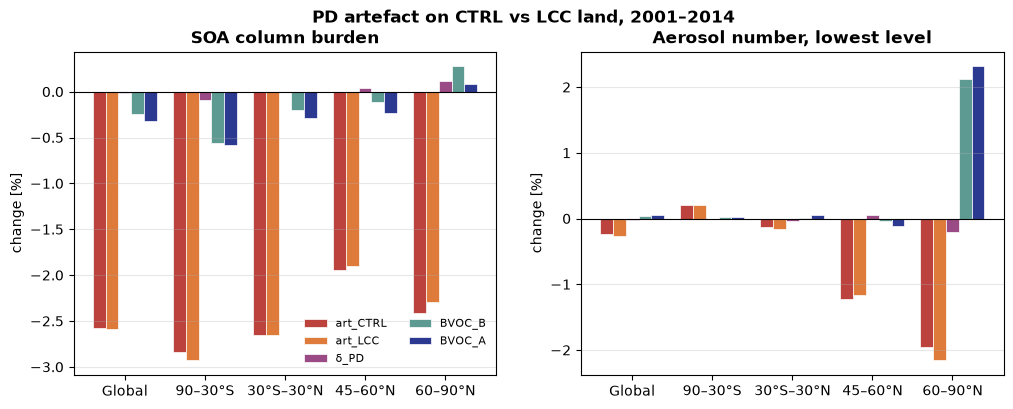

In [9]:
# Colours: project palette (src/boreal_forest_expansion/plotting/palette.py, user 2026-11-03)
COLORS = {'art_CTRL': '#BC423E', 'art_LCC': '#DE7A3A', 'δ_PD': '#9A4A84', 'BVOC_B': '#5D9A92', 'BVOC_A': '#2C3990'}
if READY:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    for ax, var, title in zip(axes, ['SOA_cb', 'N_AER_sfc'], ['SOA column burden', 'Aerosol number, lowest level']):
        shown = [k for k in COLORS if (k, var, 'Global') in CH]
        w = 0.8 / max(len(shown), 1)
        for i, k in enumerate(shown):
            ax.bar(np.arange(len(BAR_BANDS)) + (i - (len(shown) - 1) / 2) * w,
                   [CH[(k, var, b)].mean() for b in BAR_BANDS], w, color=COLORS[k], label=k,
                   edgecolor='white', linewidth=0.5)
        ax.axhline(0, color='k', lw=0.8)
        ax.set_xticks(np.arange(len(BAR_BANDS)), BAR_BANDS)
        ax.set_ylabel('change [%]'); ax.set_title(title, fontweight='semibold'); ax.grid(axis='y', alpha=0.3)
    axes[0].legend(fontsize=8, ncol=2, frameon=False)
    fig.suptitle(f'PD artefact on CTRL vs LCC land, {YEARS[0]}–{YEARS[-1]}' + ('  [TEST MODE]' if STANDIN else ''),
                 fontweight='bold')
    fig.savefig(OUT / 'figures' / 'artefact_pd_bars_by_band.png', dpi=200, bbox_inches='tight')
else:
    print('pending')

### 4b. Zonal mean SOA burden change
If δ_PD is a land effect it should peak near the changed land (46–82°N); a flat δ ≈ 0 supports design B.

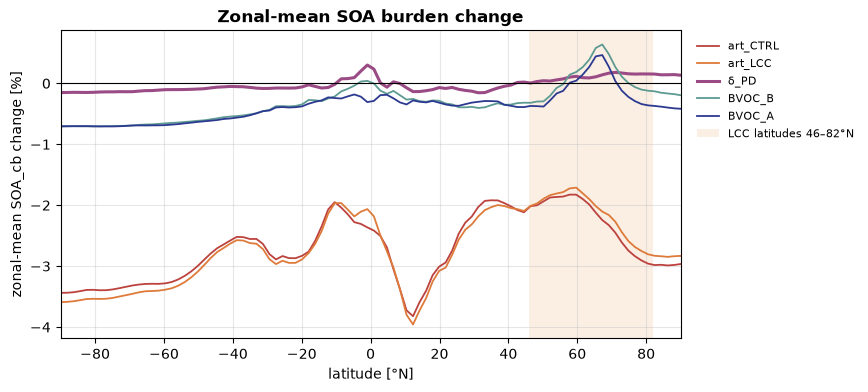

In [10]:
def zonal_pct(c1, c2, var='SOA_cb', base=None):
    # % of `base` (default case2); art in % of the interactive run
    a = F[c1][var].mean('year').mean('lon'); b = F[c2][var].mean('year').mean('lon')
    r = b if base is None else F[base][var].mean('year').mean('lon')
    return 100 * (a - b) / r

if READY:
    z = {k: zonal_pct(*PAIRS[k], base=BASE.get(k)) for k in PAIRS}
    z['δ_PD'] = z['art_LCC'] - z['art_CTRL']; z['BVOC_B'] = z['C'] - z['art_CTRL']
    fig, ax = plt.subplots(figsize=(8, 4))
    for k, col in COLORS.items():
        ax.plot(z[k]['lat'], z[k], color=col, lw=2.2 if k == 'δ_PD' else 1.3, label=k)
    ax.axhline(0, color='k', lw=0.8); ax.axvspan(46, 82, color='#f5cba7', alpha=0.3, lw=0, label='LCC latitudes 46–82°N')
    ax.set_xlabel('latitude [°N]'); ax.set_ylabel('zonal-mean SOA_cb change [%]'); ax.set_xlim(-90, 90)
    ax.legend(fontsize=8, frameon=False, loc='upper left', bbox_to_anchor=(1.01, 1)); ax.grid(alpha=0.3)
    ax.set_title('Zonal-mean SOA burden change' + ('  [TEST MODE]' if STANDIN else ''), fontweight='semibold')
    fig.savefig(OUT / 'figures' / 'artefact_pd_zonal_soa.png', dpi=200, bbox_inches='tight')
else:
    print('pending')

## 4c. Maps: where does δ_PD come from?
**Test.** If δ_PD came from the land cover, it would sit on the cells where the land changed (LCC cells, 46–82°N, **outlined in black**). If it sits somewhere else, the artefact does not depend on the boreal land. Something else differs between the LCC and CTRL run pairs.

**Identity (exact for absolute changes).** Rearranging the four runs:

δ_PD = (LCC_PD − CTRL_PD) − (LCC_PD_fBVOClccPD − CTRL_PD_fBVOCctrlPD)
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;= (LCC − CTRL with the **actual 2001–2002** emissions) − (LCC − CTRL with **2001–2014 climatology** emissions)

So δ_PD ≠ 0 wherever the LCC − CTRL difference in 2001–2002 is not the same as its 2001–2014 average.

Maps show absolute changes (mean of 2001–2002): emissions in mg m⁻² day⁻¹, SOA_cb in mg m⁻². Each panel title gives the **global mean** and the **mean over the LCC cells**, both in % of CTRL_PD over the same area.

In [11]:
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from matplotlib.ticker import MaxNLocator

ARCTIC_MIN_LAT = 40   # southern edge of the Arctic maps

# map units: emissions kg m-2 s-1 -> mg m-2 day-1
MAPSCALE = {'SFISOP': (1e6 * 86400, 'mg m$^{-2}$ day$^{-1}$'), 'SFMTERP': (1e6 * 86400, 'mg m$^{-2}$ day$^{-1}$'),
            'SOA_cb': (1.0, 'mg m$^{-2}$')}

def polar_boundary(ax):
    # round outline of a polar-stereographic map
    import matplotlib.path as mpath
    t = np.linspace(0, 2 * np.pi, 100)
    ax.set_boundary(mpath.Path(np.c_[np.sin(t), np.cos(t)] * 0.5 + 0.5), transform=ax.transAxes)

def global_map(ax, da, vmax, title, arctic=False):
    data, lon = add_cyclic_point(da.values, coord=da['lon'].values)
    pm = ax.pcolormesh(lon, da['lat'], data, cmap='RdBu_r', vmin=-vmax, vmax=vmax, transform=ccrs.PlateCarree(),
                       shading='auto', rasterized=True)
    ax.coastlines(lw=0.4, color='0.35')
    m, lonm = add_cyclic_point(LCCM.astype(float).values, coord=LCCM['lon'].values)
    ax.contour(lonm, LCCM['lat'], m, levels=[0.5], colors='k', linewidths=0.9, transform=ccrs.PlateCarree())
    if arctic:
        ax.set_extent([-180, 180, ARCTIC_MIN_LAT, 90], crs=ccrs.PlateCarree()); polar_boundary(ax)
    else:
        ax.set_global()
    ax.set_title(title, fontsize=9)
    return pm

def map_row(axes, var, keys, vmax=None, arctic=False):
    # one row of maps (one per contrast) with a shared colour scale; arctic=True: ≥40°N polar view
    sc, units = MAPSCALE[var]
    x = contrast_fields(var)
    fields = {k: x[k].mean('year') * sc for k in keys}
    if vmax is None:
        sub = (lambda f: f.where(f['lat'] >= ARCTIC_MIN_LAT, drop=True)) if arctic else (lambda f: f)
        vmax = max(fm.symmetric_vmax(sub(f), q=0.99) for f in fields.values())
    for ax, k in zip(axes, keys):
        if arctic:
            m1 = f'≥45°N {pct_of_ctrl(x[k], var, W["lat"] >= 45):+.2f} %'
        else:
            m1 = f'global {pct_of_ctrl(x[k], var):+.2f} %'
        alt = f'\n= {DEFS_ALT[k]}' if k in DEFS_ALT else ''
        t = f'{k}\n= {DEFS.get(k, "")}{alt}\n{m1}  |  LCC cells {pct_of_ctrl(x[k], var, LCCM):+.2f} %'
        pm = global_map(ax, fields[k], vmax, t, arctic=arctic)
    cb = plt.colorbar(pm, ax=list(axes), orientation='horizontal', shrink=0.5, pad=0.04, aspect=40, extend='both')
    cb.locator = MaxNLocator(nbins=9, symmetric=True); cb.update_ticks()
    cb.set_label(f'{var} change [{units}]', fontsize=9)

def maps_figure(keys, arctic, title, fname, vars_=('SFISOP', 'SFMTERP', 'SOA_cb')):
    # one row per variable, one column per contrast; global (Robinson) or Arctic (≥40°N polar) view
    n = len(keys)
    proj, h = (ccrs.NorthPolarStereo(), 4.7) if arctic else (ccrs.Robinson(), 3.9)
    fig, axes = plt.subplots(len(vars_), n, figsize=(4.4 * n, h * len(vars_)), subplot_kw=dict(projection=proj),
                             squeeze=False)
    for row, var in zip(axes, vars_):
        map_row(row, var, keys, arctic=arctic)
    view = 'Arctic view (≥40°N)' if arctic else 'global'
    fig.suptitle(f'{title}, {view}, mean {YEARS[0]}–{YEARS[-1]}  (black outline = LCC cells)', fontweight='bold',
                 y=0.95 if arctic else 0.96)
    fig.savefig(OUT / 'figures' / f'{fname}{"_arctic" if arctic else ""}.png', dpi=200, bbox_inches='tight')

### Figure A1: the artefact contrasts
Each panel title gives the contrast's name, its definition (run − run), the same contrast written with the BVOC estimates, then the means. All runs are PD; the years are the comparison years printed in section 1.

| Panel | Definition | = | In words |
|---|---|---|---|
| **art_CTRL** | CTRL_PD − CTRL_PD_fBVOCctrlPD | C − BVOC_B | the artefact on CTRL land: interactive MEGAN compared with prescribing CTRL_PD's own (climatological) emissions |
| **art_LCC** | LCC_PD − LCC_PD_fBVOClccPD | C − BVOC_A | the same test on LCC land, with LCC_PD's own emissions |
| **δ_PD** | art_LCC − art_CTRL | BVOC_B − BVOC_A | how much the artefact changes when the land changes (0 = design B exact) |

If δ_PD (3rd column) were a land effect, it would sit inside the black outlines. Rows: isoprene and monoterpene emission (the input) and SOA burden (the result).

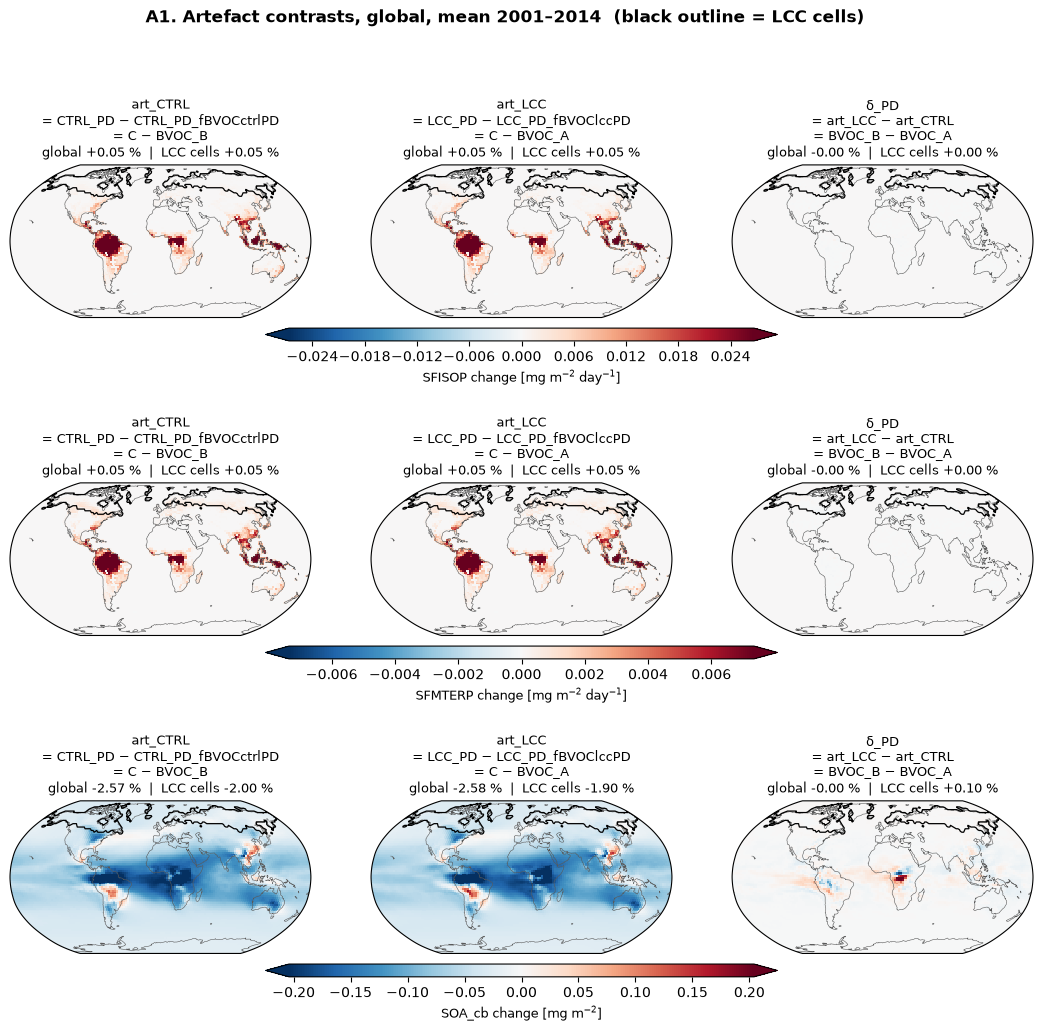

In [12]:
if READY:
    maps_figure(['art_CTRL', 'art_LCC', 'δ_PD'], False, 'A1. Artefact contrasts', 'map_artefact_delta_pd')
else:
    print('pending')

### Figure A1, Arctic view (≥40°N)
The same maps on a polar projection. The colour scale is set from the values north of 40°N, so it is finer than in the global maps. Titles give the mean **≥45°N** instead of the global mean.

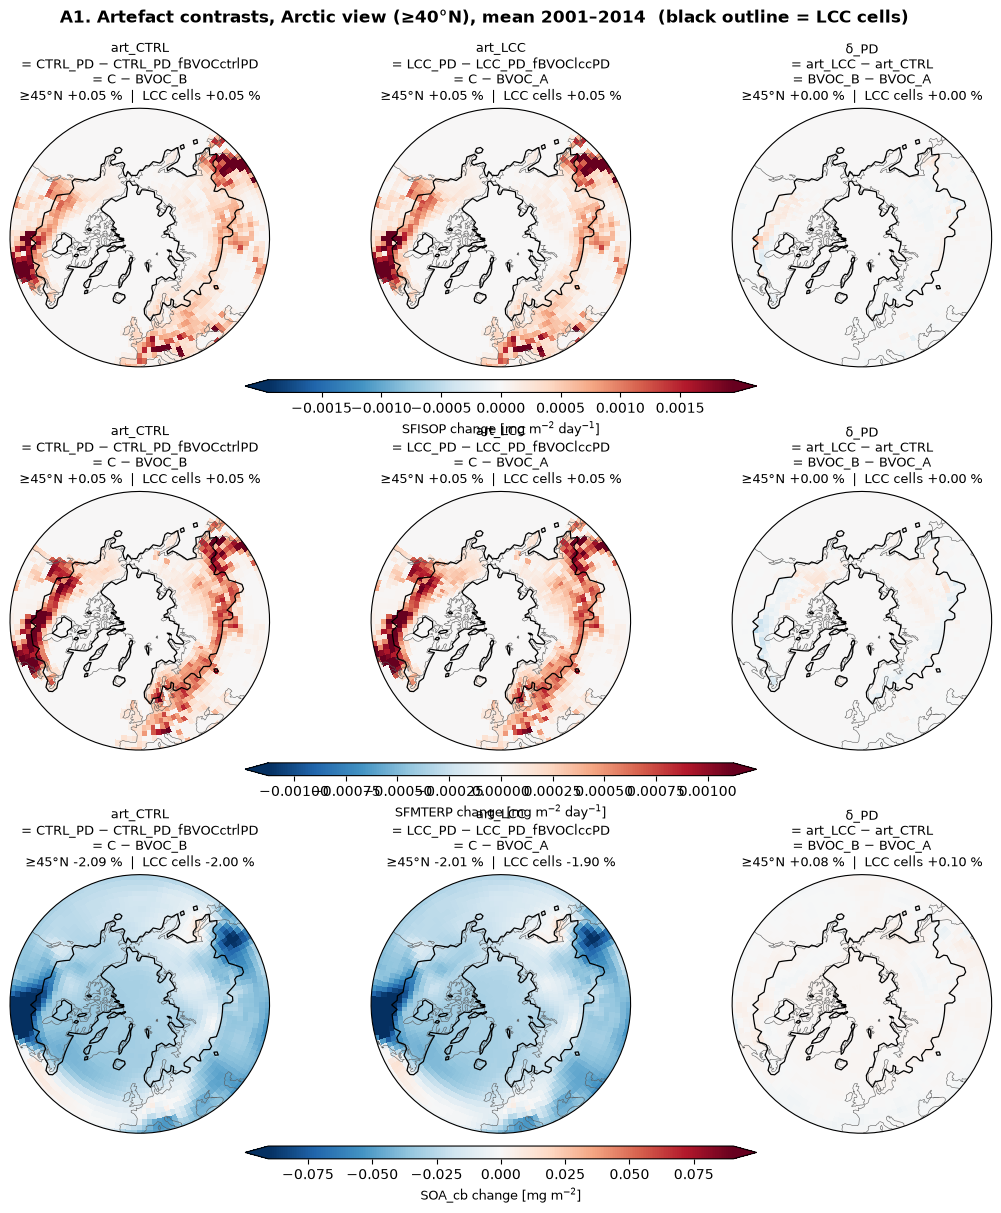

In [13]:
if READY:
    maps_figure(['art_CTRL', 'art_LCC', 'δ_PD'], True, 'A1. Artefact contrasts', 'map_artefact_delta_pd')
else:
    print('pending')

### Figure A2: the three estimates of the PD BVOC effect

| Panel | Definition | In words |
|---|---|---|
| **C** | LCC_PD − LCC_PD_fBVOCctrlPD | uncorrected `BVOC_PD`: interactive vs prescribed CTRL_PD emissions, on LCC land; it contains the artefact |
| **BVOC_B** | C − art_CTRL | design B (matched baseline): C corrected with the CTRL-land artefact |
| **BVOC_A** | LCC_PD_fBVOClccPD − LCC_PD_fBVOCctrlPD | design A: both runs prescribed, so the artefact cancels except for its land dependence |

**The three differences between them are the panels of Figure A1** (exact for absolute changes, so they are not plotted again):
- C − BVOC_B = **art_CTRL**
- C − BVOC_A = **art_LCC**
- BVOC_B − BVOC_A = **δ_PD**

The cell checks these identities numerically.

SFISOP C − BVOC_B vs art_CTRL: 8.5e-18 C − BVOC_A vs art_LCC: 1.1e-17 BVOC_B − BVOC_A vs δ_PD: 3.7e-17 (max |error| / max |field|)
SOA_cb C − BVOC_B vs art_CTRL: 0.0e+00 C − BVOC_A vs art_LCC: 0.0e+00 BVOC_B − BVOC_A vs δ_PD: 0.0e+00 (max |error| / max |field|)


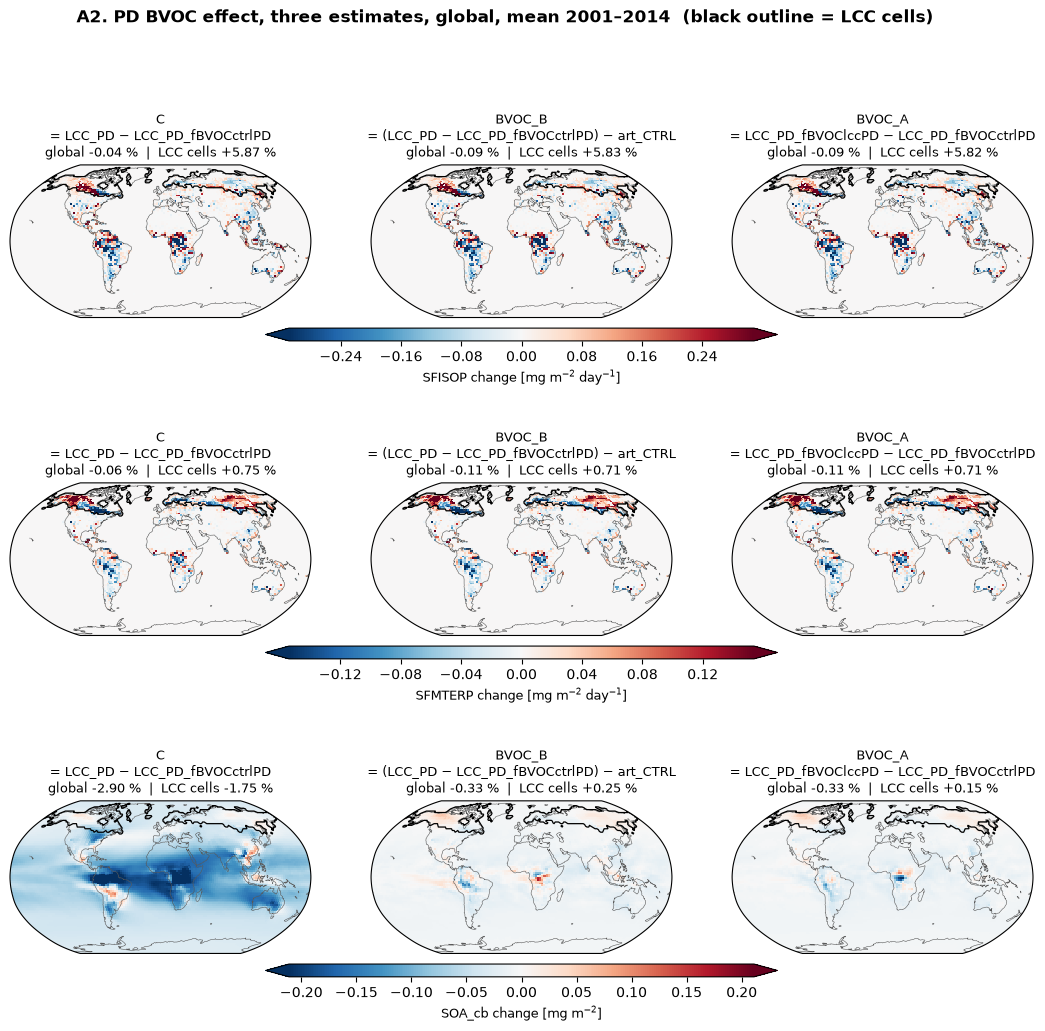

In [14]:
if READY:
    # identities: C − BVOC_B = art_CTRL, C − BVOC_A = art_LCC, BVOC_B − BVOC_A = δ_PD (absolute fields)
    for var in ('SFISOP', 'SOA_cb'):
        x = contrast_fields(var)
        err = {f'{a} − {b} vs {k}': float(abs(x[a] - x[b] - x[k]).max() / abs(x[k]).max())
               for a, b, k in [('C', 'BVOC_B', 'art_CTRL'), ('C', 'BVOC_A', 'art_LCC'), ('BVOC_B', 'BVOC_A', 'δ_PD')]}
        print(var, ' '.join(f'{k}: {v:.1e}' for k, v in err.items()), '(max |error| / max |field|)')
    maps_figure(['C', 'BVOC_B', 'BVOC_A'], False, 'A2. PD BVOC effect, three estimates', 'map_bvoc_estimates')
else:
    print('pending')

### Figure A2, Arctic view (≥40°N)

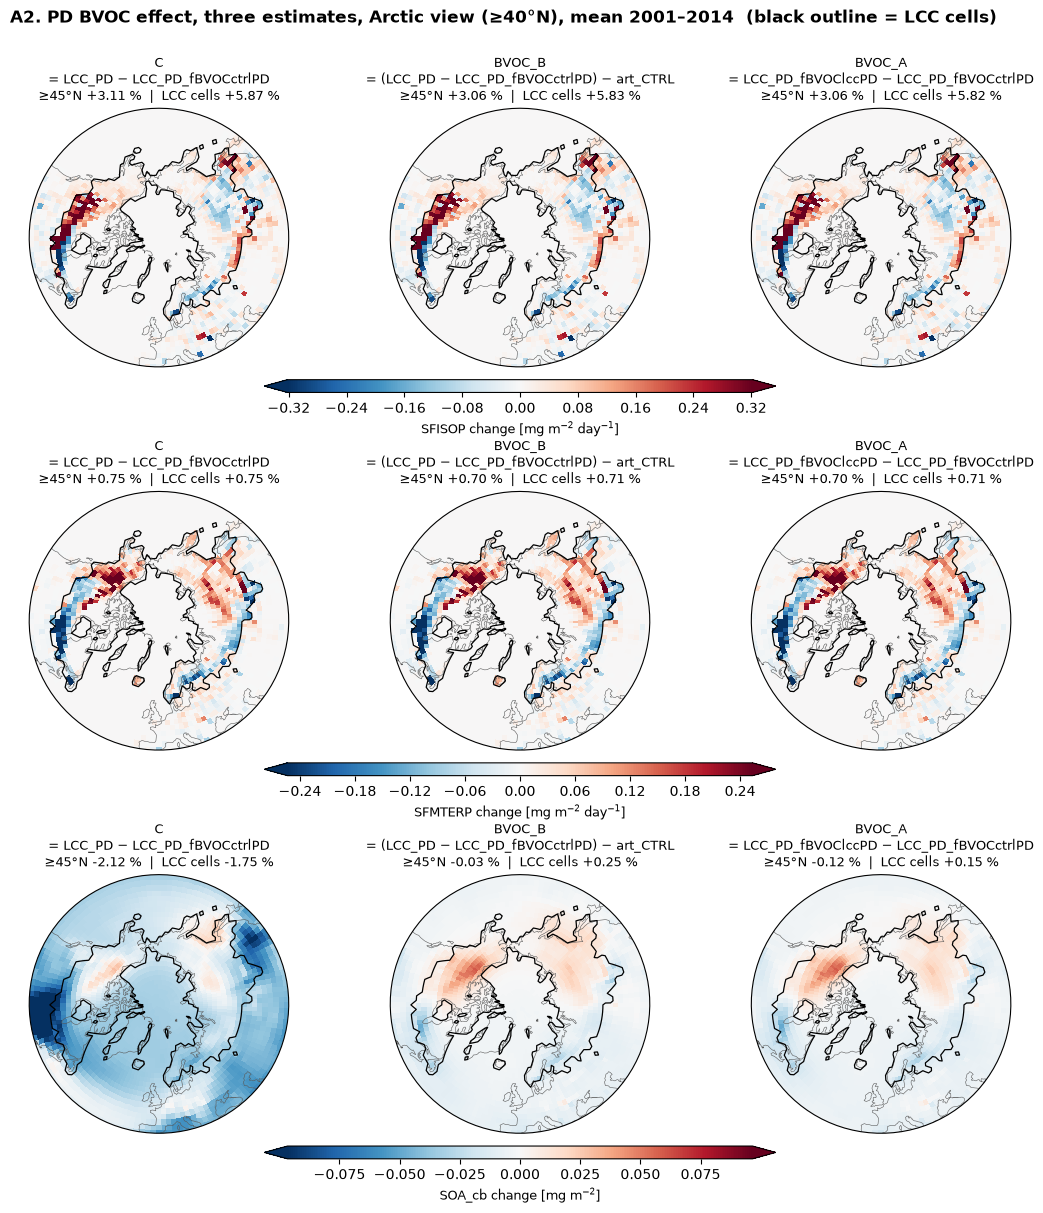

In [15]:
if READY:
    maps_figure(['C', 'BVOC_B', 'BVOC_A'], True, 'A2. PD BVOC effect, three estimates', 'map_bvoc_estimates')
else:
    print('pending')

### Figure B: why δ_PD is where it is
By the identity above, δ_PD (right) = **LCC − CTRL with the actual emissions of the comparison years** (middle) − **LCC − CTRL with the climatology** (left).
- Left: the two fBVOC runs get the 2001–2014 climatologies of LCC_PD and CTRL_PD. Their difference is the 14-year mean LCC − CTRL difference.
- Middle: the two interactive runs, in the comparison years only.

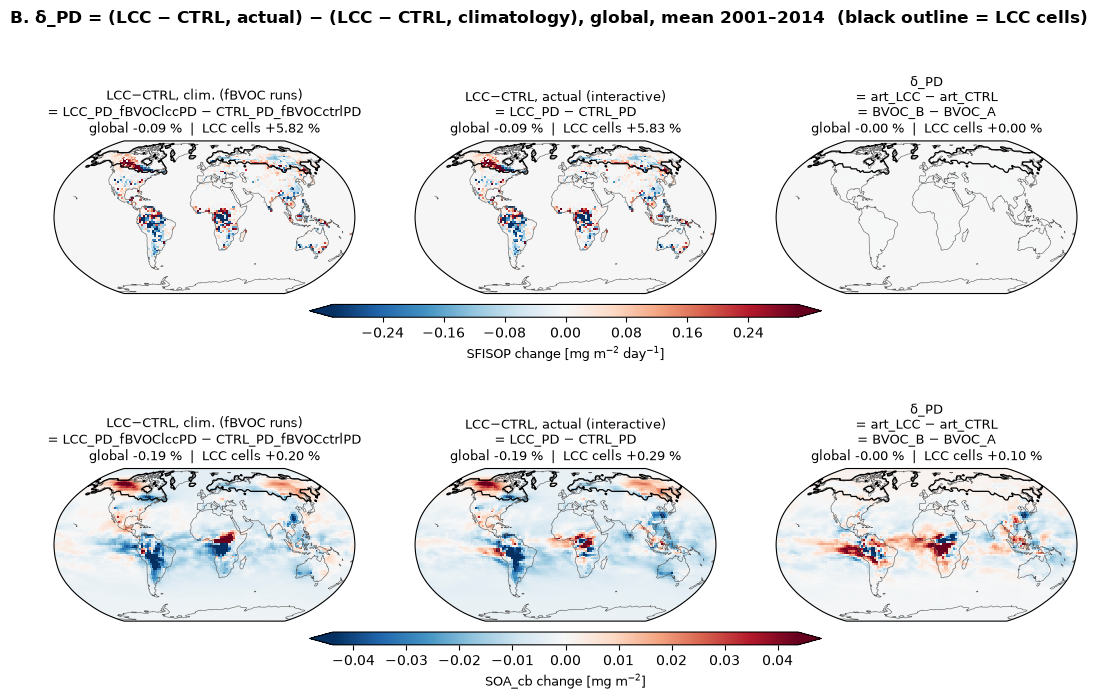

In [16]:
if READY:
    KEYS_B = ['LCC−CTRL, clim. (fBVOC runs)', 'LCC−CTRL, actual (interactive)', 'δ_PD']
    maps_figure(KEYS_B, False, 'B. δ_PD = (LCC − CTRL, actual) − (LCC − CTRL, climatology)', 'map_delta_pd_identity',
                vars_=('SFISOP', 'SOA_cb'))
else:
    print('pending')

### Figure B, Arctic view (≥40°N)

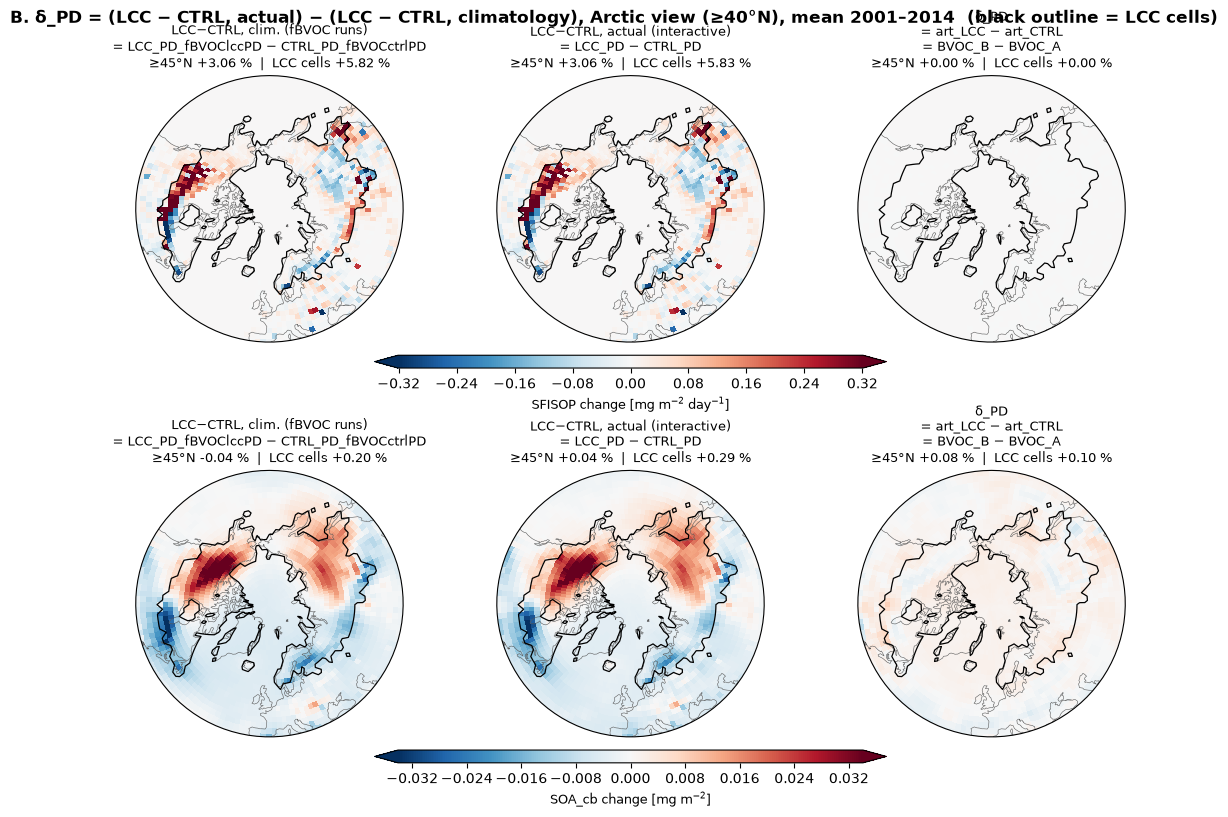

In [17]:
if READY:
    maps_figure(KEYS_B, True, 'B. δ_PD = (LCC − CTRL, actual) − (LCC − CTRL, climatology)', 'map_delta_pd_identity',
                vars_=('SFISOP', 'SOA_cb'))
else:
    print('pending')

### Figure C: is 2001–2002 special? LCC_PD − CTRL_PD, interactive runs, 2001–2014
If the LCC − CTRL difference outside the boreal zone is larger in 2001–2002 than later, then δ_PD measures a transient between the two run chains, not the land cover. CTRL_PD and LCC_PD come from different spin-ups: LCC adds a 100-yr land-only BGC spin-up (CLAUDE.md, Spin-up chains). Leaf area (TLAI) and vegetation carbon (TOTVEGC) test whether the vegetation is the cause.

2001  2002  2003  2004  2005  2006  2007  2008  2009  2010  2011  2012  2013  2014  mean 2001–14
variable band                                                                                                                            
SFISOP   south of 45°N (land identical) -1.57 -0.69  0.16 -0.10 -0.14  0.35 -0.20  0.30  0.10  0.03  0.20 -0.18  0.16 -0.49         -0.15
         45–90°N (LCC zone)              4.49  3.46  3.44  3.71  3.04  2.99  3.16  3.32  3.09  1.06  2.14  2.26  3.23  3.49          3.06
SFMTERP  south of 45°N (land identical) -1.39 -0.60 -0.01 -0.27 -0.04  0.23 -0.09  0.21  0.06 -0.04  0.13 -0.11  0.01 -0.32         -0.16
         45–90°N (LCC zone)              1.43  2.12  1.40  1.23  0.91  0.63  0.47  0.84  0.29 -0.14  0.26 -0.14  0.14  0.49          0.71
SOA_cb   south of 45°N (land identical) -1.46 -1.41 -0.73 -0.29 -0.58 -0.07  0.22  0.12  0.23  0.58  0.36 -0.32  0.51 -0.05         -0.21
         45–90°N (LCC zone)              0.43 -1.49 -1.76 -0.64 -1.49 -0.48  0.88  0.32  0.49  1.77  0.44 -1.14  1.38  1.82          0.04
TLAI     south of 45°N (land identical) -0.55 -0.33 -0.29 -0.32  0.01  0.10 -0.02  0.04 -0.04 -0.09 -0.10 -0.13 -0.12 -0.17         -0.14
         45–90°N (LCC zone)             -1.25 -1.00 -1.19 -1.18 -1.84 -2.00 -1.80 -2.27 -1.95 -2.19 -2.26 -2.31 -2.52 -2.84         -1.90
TOTVEGC  south of 45°N (land identical) -0.06 -0.05 -0.06 -0.04 -0.02 -0.03 -0.02 -0.02 -0.04 -0.04 -0.04 -0.04 -0.03 -0.03         -0.04
         45–90°N (LCC zone)              2.33  2.38  2.37  2.36  2.36  2.35  2.36  2.34  2.35  2.34  2.34  2.34  2.34  2.33          2.35

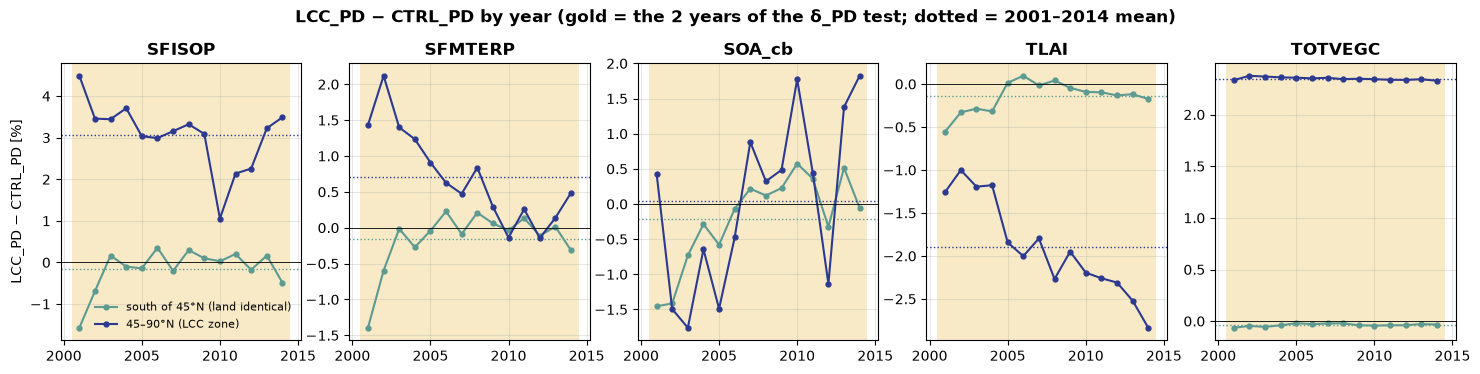

In [18]:
def yearly_band_series(alias, comp, cls, var, lo, hi):
    # 2001–2014 yearly band mean of alias/var (cos-lat weighted; land NaNs ignored)
    f = sorted(PROC.glob(f'{alias}_{comp}_{cls}_*-*.nc'))[0]
    ds = xr.open_dataset(f)
    return fm.area_weighted_mean(fm.annual_mean(ds[var], ds), lat_min=lo, lat_max=hi)

if READY:
    SERIES = [('atm', 'BVOC', 'SFISOP'), ('atm', 'BVOC', 'SFMTERP'), ('atm', 'SOA', 'SOA_cb'),
              ('lnd', 'LAND', 'TLAI'), ('lnd', 'BIOGEOCHEM', 'TOTVEGC')]
    BANDS_TS = {'south of 45°N (land identical)': ((-90, 45), '#5D9A92'), '45–90°N (LCC zone)': ((45, 90), '#2C3990')}
    fig, axes = plt.subplots(1, len(SERIES), figsize=(18, 3.6), sharex=True)
    ts_rows = []
    for ax, (comp, cls, var) in zip(axes, SERIES):
        for lab, ((lo, hi), col) in BANDS_TS.items():
            c = yearly_band_series('CTRL_PD', comp, cls, var, lo, hi)
            l = yearly_band_series('LCC_PD', comp, cls, var, lo, hi)
            p = 100 * (l - c) / c
            yrs = p['year'].values if 'year' in p.dims else np.arange(2001, 2001 + p.size)
            ax.plot(yrs, p.values, '-o', ms=3.5, color=col, label=lab)
            ax.axhline(float(p.mean()), color=col, ls=':', lw=1)
            ts_rows.append(dict(variable=var, band=lab, **{str(y): round(float(v), 2) for y, v in zip(yrs, p.values)},
                                **{'mean 2001–14': round(float(p.mean()), 2)}))
        ax.axvspan(YEARS[0] - 0.5, YEARS[-1] + 0.5, color='#EBC45C', alpha=0.35, lw=0)
        ax.axhline(0, color='k', lw=0.6); ax.set_title(var, fontweight='semibold'); ax.grid(alpha=0.3)
    axes[0].set_ylabel('LCC_PD − CTRL_PD [%]')
    axes[0].legend(fontsize=8, frameon=False, loc='lower right')
    fig.suptitle('LCC_PD − CTRL_PD by year (gold = the 2 years of the δ_PD test; dotted = 2001–2014 mean)',
                 fontweight='bold', y=1.03)
    fig.savefig(OUT / 'figures' / 'lcc_minus_ctrl_timeseries.png', dpi=200, bbox_inches='tight')
    TS = pd.DataFrame(ts_rows).set_index(['variable', 'band'])
    TS.to_csv(OUT / 'tables' / 'lcc_minus_ctrl_by_year.csv')
    display(TS)
else:
    print('pending')

## 4d. How much does the artefact depend on the land?
Each global-mean change is split into the parts that come from three regions: **LCC cells** (land changed), **other cells ≥45°N**, and **south of 45°N** (land identical). Each part is the region's area-weighted sum ÷ the global area ÷ the global CTRL_PD mean, in %. The three parts add up to the global value. NET_toa is in W m⁻².

Two ratios:
- **R_global** = |δ_PD| / |BVOC_B|, global (the rule in section 3).
- **R_LCC** = |δ_PD| / |BVOC_B|, both as means over the LCC cells only. This is where a land dependence would show up.

In [19]:
if READY:
    REG = {'LCC cells': LCCM, 'other ≥45°N': (W['lat'] >= 45) & ~LCCM, '<45°N': W['lat'] < 45}
    rows = []
    for var in ['SFISOP', 'SFMTERP', 'cb_SOA_LV', 'cb_SOA_SV', 'SOA_cb', 'N_AER_sfc', 'CDNC_incld', 'NET_toa']:
        rel = VARS[var][3]
        x = contrast_fields(var)
        gtot = float(area_mean(F['ctrl'][var]).mean('year'))
        wsum = float(W.where(F['ctrl'][var].isel(year=0).notnull()).sum())
        for k in ['δ_PD', 'BVOC_B']:
            r = dict(variable=var, contrast=k)
            for rn, m in REG.items():
                part = float((x[k].mean('year') * W).where(m).sum() / wsum)
                r[rn] = 100 * part / gtot if rel else part
            r['global'] = sum(r[rn] for rn in REG)
            r['mean over LCC cells'] = pct_of_ctrl(x[k], var, LCCM) if rel else float(area_mean(x[k], LCCM).mean('year'))
            rows.append(r)
    HM = pd.DataFrame(rows).set_index(['variable', 'contrast'])
    for var in HM.index.get_level_values(0).unique():
        d, b = HM.loc[(var, 'δ_PD')], HM.loc[(var, 'BVOC_B')]
        HM.loc[(var, 'δ_PD'), 'R_global'] = abs(d['global']) / abs(b['global'])
        HM.loc[(var, 'δ_PD'), 'R_LCC'] = abs(d['mean over LCC cells']) / abs(b['mean over LCC cells'])
        HM.loc[(var, 'δ_PD'), 'share of global δ from <45°N [%]'] = 100 * d['<45°N'] / d['global']
    HM.round(3).to_csv(OUT / 'tables' / 'delta_pd_by_region.csv')
    display(HM.round(3))

    # year by year over the LCC cells (2 years: sign agreement = more than noise)
    print('\nSOA_cb over the LCC cells, by year [% of CTRL_PD]:')
    x = contrast_fields('SOA_cb')
    ctrl_l = area_mean(F['ctrl']['SOA_cb'], LCCM)
    for k in ['art_CTRL', 'art_LCC', 'δ_PD', 'BVOC_B']:
        v = 100 * area_mean(x[k], LCCM) / ctrl_l
        print(f'  {k:9s}', '  '.join(f'{y}: {val:+.2f}' for y, val in zip(YEARS, v.values)))
else:
    print('pending')

LCC cells  other ≥45°N  <45°N  global  mean over LCC cells  R_global  R_LCC  share of global δ from <45°N [%]
variable   contrast                                                                                                               
SFISOP     δ_PD          0.000        0.000 -0.000  -0.000                0.003     0.000  0.000                           160.979
           BVOC_B        0.047        0.009 -0.146  -0.090                5.827       NaN    NaN                               NaN
SFMTERP    δ_PD          0.000        0.000 -0.000  -0.000                0.000     0.000  0.000                           139.102
           BVOC_B        0.024        0.016 -0.150  -0.109                0.706       NaN    NaN                               NaN
cb_SOA_LV  δ_PD         -0.002        0.000  0.018   0.016               -0.176     0.070  0.043                           110.424
           BVOC_B        0.044        0.003 -0.282  -0.236                4.139       NaN    NaN                               NaN
cb_SOA_SV  δ_PD          0.001       -0.001  0.039   0.039                0.110     0.260  0.090                           100.053
           BVOC_B        0.010        0.001 -0.160  -0.149                1.214       NaN    NaN                               NaN
SOA_cb     δ_PD          0.003        0.003 -0.008  -0.002                0.097     0.006  0.393                           438.016
           BVOC_B        0.008       -0.010 -0.324  -0.327                0.248       NaN    NaN                               NaN
N_AER_sfc  δ_PD         -0.001        0.001 -0.027  -0.027               -0.025     0.881  0.028                            99.687
           BVOC_B        0.030        0.001 -0.000   0.031                0.870       NaN    NaN                               NaN
CDNC_incld δ_PD          0.007        0.007  0.037   0.051                0.121     0.595  0.303                            72.345
           BVOC_B        0.022        0.005  0.058   0.086                0.400       NaN    NaN                               NaN
NET_toa    δ_PD         -0.001        0.000 -0.013  -0.014               -0.009     4.451  0.195                            97.745
           BVOC_B       -0.003       -0.001  0.001  -0.003               -0.047       NaN    NaN                               NaN


SOA_cb over the LCC cells, by year [% of CTRL_PD]:
  art_CTRL  2001: -3.23  2002: -3.50  2003: -2.25  2004: -2.60  2005: +0.95  2006: +0.66  2007: -2.57  2008: +0.39  2009: -3.89  2010: -2.42  2011: -5.59  2012: -2.06  2013: -1.30  2014: -1.06
  art_LCC   2001: -1.54  2002: -4.51  2003: -3.46  2004: -2.55  2005: -0.32  2006: -0.78  2007: -2.47  2008: +0.09  2009: -3.33  2010: -0.14  2011: -5.69  2012: -4.04  2013: +0.49  2014: +1.06
  δ_PD      2001: +1.68  2002: -1.01  2003: -1.21  2004: +0.05  2005: -1.27  2006: -1.43  2007: +0.09  2008: -0.30  2009: +0.56  2010: +2.28  2011: -0.09  2012: -1.97  2013: +1.79  2014: +2.13
  BVOC_B    2001: +2.00  2002: -1.60  2003: -2.05  2004: -1.09  2005: -2.32  2006: -1.19  2007: -0.04  2008: -0.56  2009: +0.58  2010: +3.25  2011: +1.80  2012: -0.19  2013: +2.22  2014: +2.61


### Reading the maps and the table (2001–2002, 2 years)
_Signs of δ_PD and art below converted to the 2026-11-07 convention (interactive − prescribed); the figures change sign only after a rerun._
**1. δ_PD does not sit on the changed land.** In Figure A1 (3rd column) δ_PD is in the tropics: Amazon, Congo, SE Asia. Inside the black outlines it is close to 0. **About 100 % of the global δ_PD comes from south of 45°N** (SFISOP 101 %, SFMTERP 108 %, SOA_cb 102 %, CDNC 97 %), where LCC and CTRL have the same land. The LCC cells give +0.01 percentage points of the −1.0 % δ_PD in SOA_cb.

**1b. Arctic view (Figures A1 and B, polar maps).** North of 45°N, δ_PD is small and patchy. It does not follow the LCC outline: isolated cells of both signs, with the largest isoprene patch (positive) in eastern Siberia. Means ≥45°N: isoprene δ +0.8 % vs BVOC_B +4.0 %, monoterpene +1.0 % vs +1.8 %, SOA_cb +0.26 % vs −0.18 %. For SOA_cb both are near zero and flip sign between the 2 years.

**2. Where it comes from (Figure B).** In 2001–2002 the interactive LCC_PD emits about 1 % less isoprene in the tropics than CTRL_PD (middle). Over 2001–2014 this gap averages out in the climatologies (left). δ_PD is the difference between the two. It looks like the middle panel, which is also why the δ_PD and BVOC_B maps look alike in the tropics (Figure A2 vs Figure B).

**3. Why 2001–2002 (Figure C).** South of 45°N, LCC_PD − CTRL_PD isoprene is −1.6 % (2001) and −0.7 % (2002), then about 0 % from 2003 to 2014. Leaf area follows the same path (TLAI −0.55 %, −0.33 %, then ≈ 0 from 2005). So in the first years the LCC chain's tropical vegetation starts slightly lower than CTRL's and then converges *(inference (b): LCC adds a 100-yr land-only BGC spin-up, so its tropical vegetation starts from a slightly different state; not checked in the restart files)*. The 2 test years are exactly those years.

**4. How much?**

| | δ_PD | BVOC_B | ratio |
|---|---|---|---|
| SOA_cb, global | −1.0 % | −1.4 % | R_global ≈ 0.7: **large**, but it is a tropical spin-up offset, not the boreal land |
| SOA_cb, LCC cells | +0.3 % (years +1.7, −1.0) | +0.2 % (years +2.0, −1.6) | both are noise: the 2 years have opposite signs |
| SFISOP, LCC cells | +1.0 % | +7.1 % | R_LCC = 0.14: **small** |
| SFMTERP, LCC cells | +1.1 % | +1.8 % | R_LCC = 0.59: moderate (MTERP's boreal BVOC effect is small) |
| N_AER_sfc, global | +0.01 % | +0.06 % | δ ≈ 0 |

**So:** the artefact does depend on *which run pair* (LCC chain vs CTRL chain) in 2001–2002, by about 1 % of global SOA_cb. That is as large as the global BVOC_B. But almost all of it is a tropical vegetation offset in the first two years, and the boreal land cover adds almost nothing. Over the LCC cells, δ_PD is small for isoprene (~14 % of BVOC_B). For SOA_cb, δ_PD and BVOC_B over the LCC cells cannot be told apart from noise with 2 years.

**Consequence for section 3.** The verdict there ("design A worth it") rests on R_global, and R_global is driven by this tropical offset, not by the land. The same offset is also inside BVOC_B globally: in the tropics BVOC_B = actual LCC − actual CTRL emissions. Over 2001–2014 that offset averages to −0.15 % (isoprene). The decision rule needs revisiting, e.g. R over the LCC cells or ≥45°N only, or the 14e run extended past 2004 so the test years are after the offset fades.

## 4e. Why BVOC_A is not 0 outside the changed cells: LCC_PD − CTRL_PD emissions, 2001–2014
Both runs of BVOC_A prescribe emissions: LCC_PD_fBVOClccPD reads the 2001–2014 climatology of LCC_PD, LCC_PD_fBVOCctrlPD that of CTRL_PD. So BVOC_A's emission change is exactly **mean(LCC_PD) − mean(CTRL_PD) over 2001–2014**, also outside the LCC cells. This section tests, cell by cell, whether that difference is more than noise. It uses the interactive runs, 2001–2014, not only the comparison years.

**Test.** For each cell, the yearly differences d_y = LCC_PD − CTRL_PD give a mean D and a t-statistic t = D / (sd(d_y) / √n). A cell is significant where |t| exceeds the two-sided 5 % critical value; the maps hatch the emitting cells that are **not** significant (the project convention, as in the forcing and MEGAN maps), and the tables count the significant ones ("marked"). Only **emitting cells** are tested: CTRL_PD mean ≥ 1 % of the 99th-percentile cell. Without this, deserts and tundra with tiny but very steady emissions get marked for trivial differences. If the differences were pure noise, about 5 % of the emitting cells would be marked. The table also gives the share of the summed local difference |D| that sits in marked cells, so a cell counts by how much it differs. This is done twice: 2001–2014 (what the climatologies contain), and 2003–2014 (without the 2001–2002 offset of section 4c).

**Caveat.** The test treats the years as independent. Vegetation has memory from year to year, so the share of marked cells is somewhat too high (b).

Regions: LCC cells, other cells ≥45°N, south of 45°N. Totals are in Tg yr⁻¹, using cell area from a regular-grid spherical approximation.

In [20]:
from scipy import stats

def yearly_atm(alias, cls, var):
    # yearly means 2001–2014 of an interactive run (whole processed span)
    f = sorted(PROC.glob(f'{alias}_atm_{cls}_*-*.nc'))[0]
    ds = xr.open_dataset(f)
    return fm.annual_mean(ds[var], ds).load()

if READY:
    _lat = np.deg2rad(F['ctrl']['SOA_cb']['lat'])
    _dlat = np.deg2rad(float(abs(np.diff(F['ctrl']['SOA_cb']['lat'].values[:2])[0])))
    _dlon = np.deg2rad(float(abs(np.diff(F['ctrl']['SOA_cb']['lon'].values[:2])[0])))
    AREA = 6.371e6 ** 2 * _dlon * _dlat * np.cos(_lat) * xr.ones_like(W)   # m2
    TG = lambda x: float((x * AREA).sum()) * 365 * 86400 / 1e9            # kg m-2 s-1 -> Tg yr-1
    EMS, EMITS = {}, {}   # var -> {period: (D, t, sig)}; var -> emitting-cell mask
    rows = []
    for var in ('SFISOP', 'SFMTERP'):
        c, l = yearly_atm('CTRL_PD', 'BVOC', var), yearly_atm('LCC_PD', 'BVOC', var)
        cm = c.mean('year')
        emits = cm >= 0.01 * float(cm.quantile(0.99))   # emitting cells: ≥ 1 % of the 99th-percentile cell
        EMITS[var] = emits
        EMS[var] = {}
        for period, (y0, y1) in {'2001–2014': (2001, 2014), '2003–2014': (2003, 2014)}.items():
            d = (l - c).sel(year=slice(y0, y1))
            n = d.sizes['year']
            D = d.mean('year'); t = D / (d.std('year', ddof=1) / np.sqrt(n))
            sig = (abs(t) > stats.t.ppf(0.975, n - 1)) & emits
            EMS[var][period] = (D, t, sig)
            for rn, m in {'LCC cells': LCCM, 'other ≥45°N': (W['lat'] >= 45) & ~LCCM, '<45°N': W['lat'] < 45}.items():
                rows.append({'variable': var, 'period': period, 'region': rn,
                             'net LCC−CTRL [Tg/yr]': TG(D.where(m, 0)),
                             'sum |D| [Tg/yr]': TG(abs(D).where(m, 0)),
                             'CTRL_PD total [Tg/yr]': TG(c.sel(year=slice(y0, y1)).mean('year').where(m, 0)),
                             'marked cells [%] (5 % = noise)': 100 * float(sig.where(m & emits).mean()),
                             'share of sum |D| in marked cells [%]': 100 * TG(abs(D).where(m & sig, 0)) / TG(abs(D).where(m, 0))})
    SIG = pd.DataFrame(rows).set_index(['variable', 'period', 'region'])
    SIG.round(3).to_csv(OUT / 'tables' / 'lcc_minus_ctrl_emission_significance.csv')
    display(SIG.round(3))
else:
    print('pending')

net LCC−CTRL [Tg/yr]  sum |D| [Tg/yr]  CTRL_PD total [Tg/yr]  marked cells [%] (5 % = noise)  share of sum |D| in marked cells [%]
variable period    region                                                                                                                                         
SFISOP   2001–2014 LCC cells                   0.240            0.646                  4.126                          84.541                                70.518
                   other ≥45°N                 0.046            0.111                  5.232                          38.009                                56.610
                   <45°N                      -0.744            2.797                500.593                          12.370                                22.407
         2003–2014 LCC cells                   0.234            0.646                  4.156                          84.058                                70.195
                   other ≥45°N                 0.041            0.097                  5.285                          33.484                                52.508
                   <45°N                       0.080            2.593                500.443                          12.648                                27.101
SFMTERP  2001–2014 LCC cells                   0.035            0.598                  4.976                          88.930                                90.173
                   other ≥45°N                 0.023            0.063                  3.365                          62.646                                83.568
                   <45°N                      -0.217            0.710                136.238                          20.092                                33.633
         2003–2014 LCC cells                   0.027            0.600                  5.006                          89.114                                90.484
                   other ≥45°N                 0.018            0.054                  3.392                          59.533                                80.795
                   <45°N                      -0.026            0.640                136.236                          19.630                                34.499

### Figure D: LCC_PD − CTRL_PD emissions, with significance
Colours: mean difference. Hatching: emitting cells where it is **not** significant (|t| ≤ critical value, 5 %); unhatched coloured cells are significant. Non-emitting cells (deserts, ice, ocean) are not tested and not hatched. Black outline: LCC cells. Left: 2001–2014, i.e. exactly what BVOC_A's emission change contains. Right: 2003–2014.

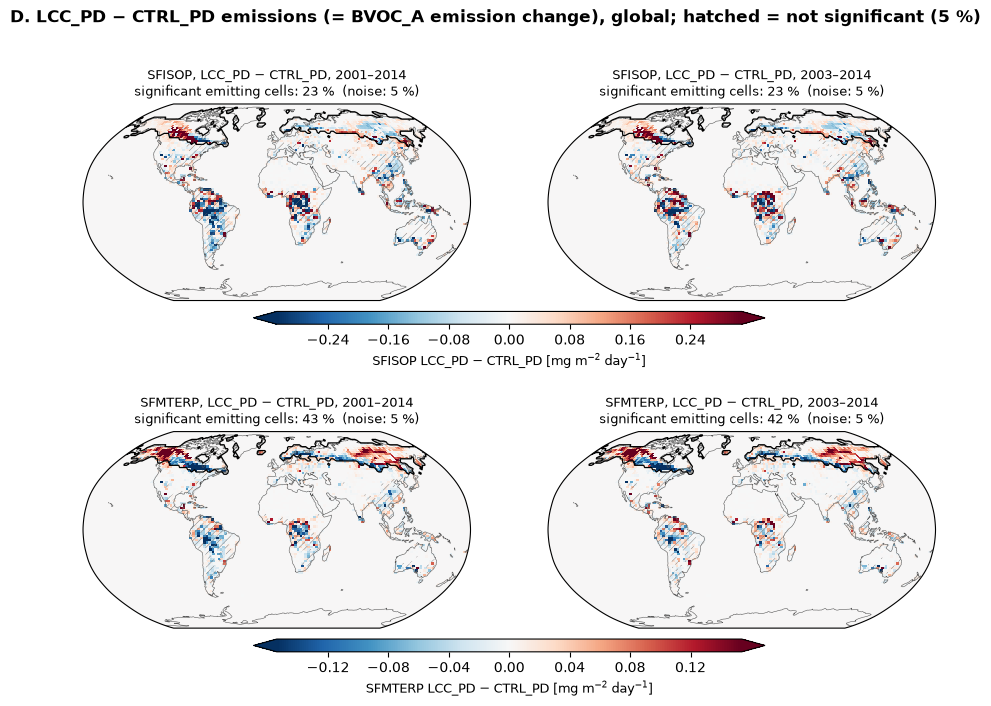

In [21]:
def sig_maps(arctic):
    periods = ['2001–2014', '2003–2014']
    proj, h = (ccrs.NorthPolarStereo(), 4.9) if arctic else (ccrs.Robinson(), 3.9)
    fig, axes = plt.subplots(2, 2, figsize=(11, 2 * h), subplot_kw=dict(projection=proj))
    for row, var in zip(axes, ('SFISOP', 'SFMTERP')):
        sc, units = MAPSCALE[var]
        sub = (lambda f: f.where(f['lat'] >= ARCTIC_MIN_LAT, drop=True)) if arctic else (lambda f: f)
        vmax = max(fm.symmetric_vmax(sub(EMS[var][p][0] * sc), q=0.99) for p in periods)
        for ax, p in zip(row, periods):
            D, t, sig = EMS[var][p]
            area_sel = (W['lat'] >= 45) if arctic else xr.ones_like(W, dtype=bool)
            share = 100 * float(sig.where(area_sel & EMITS[var]).mean())
            pm = global_map(ax, D * sc, vmax, f'{var}, LCC_PD − CTRL_PD, {p}\n'
                            f'significant emitting cells{" ≥45°N" if arctic else ""}: {share:.0f} %  (noise: 5 %)', arctic=arctic)
            fm.add_stippling(ax, EMITS[var] & ~sig, style='lines', zorder=4)   # hatch = NOT significant (project convention)
        cb = plt.colorbar(pm, ax=list(row), orientation='horizontal', shrink=0.6, pad=0.04, aspect=40, extend='both')
        cb.locator = MaxNLocator(nbins=9, symmetric=True); cb.update_ticks()
        cb.set_label(f'{var} LCC_PD − CTRL_PD [{units}]', fontsize=9)
    view = 'Arctic view (≥40°N)' if arctic else 'global'
    fig.suptitle(f'D. LCC_PD − CTRL_PD emissions (= BVOC_A emission change), {view}; hatched = not significant (5 %)',
                 fontweight='bold', y=0.97 if not arctic else 0.95)
    fig.savefig(OUT / 'figures' / f'map_lcc_minus_ctrl_emission_significance{"_arctic" if arctic else ""}.png',
                dpi=200, bbox_inches='tight')

if READY:
    sig_maps(False)
else:
    print('pending')

### Figure D, Arctic view (≥40°N)

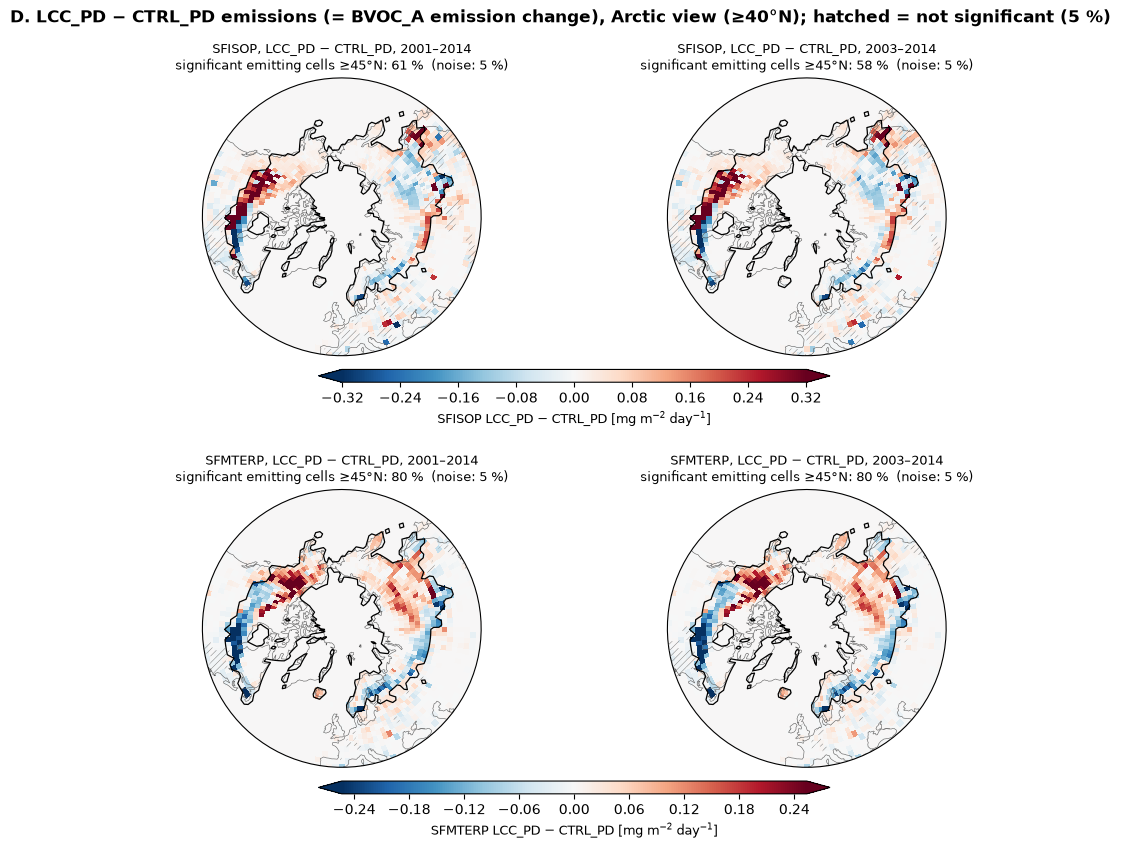

In [22]:
if READY:
    sig_maps(True)
else:
    print('pending')

### Figure D in % of CTRL_PD
The same differences as in Figure D, divided by CTRL_PD's mean emission in each cell. In absolute units the tropics saturate the colour scale because their emissions are large (isoprene ~15 mg m⁻² day⁻¹ against a colour limit of ~0.25): a 1–2 % change already looks dark. In % the land-cover signal north of 45°N stands out, and the tropics show how small their changes are. Only emitting cells are coloured (same definition as above); hatching as in Figure D.

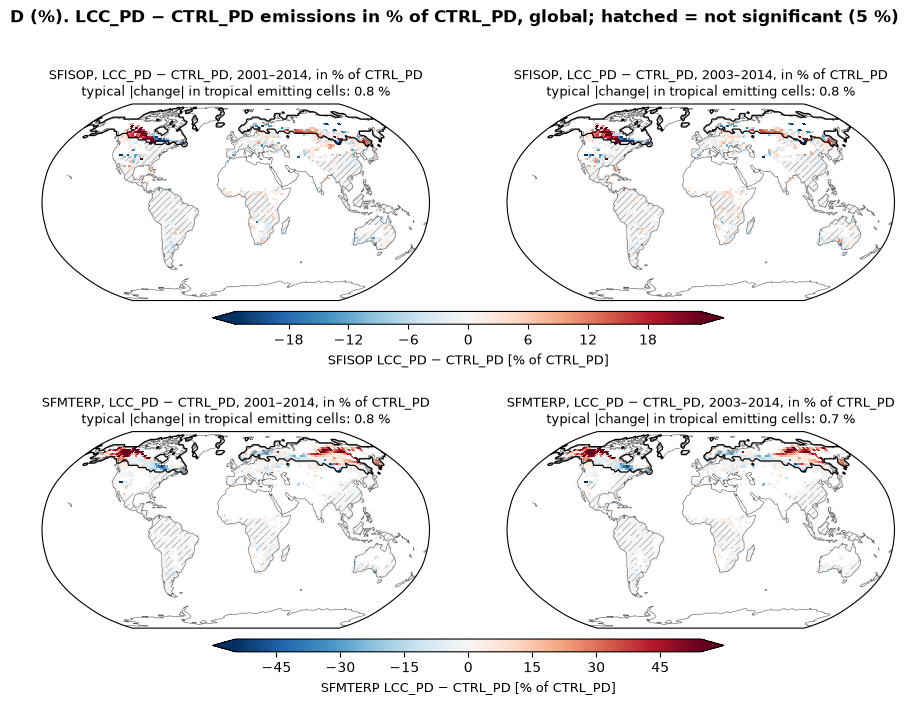

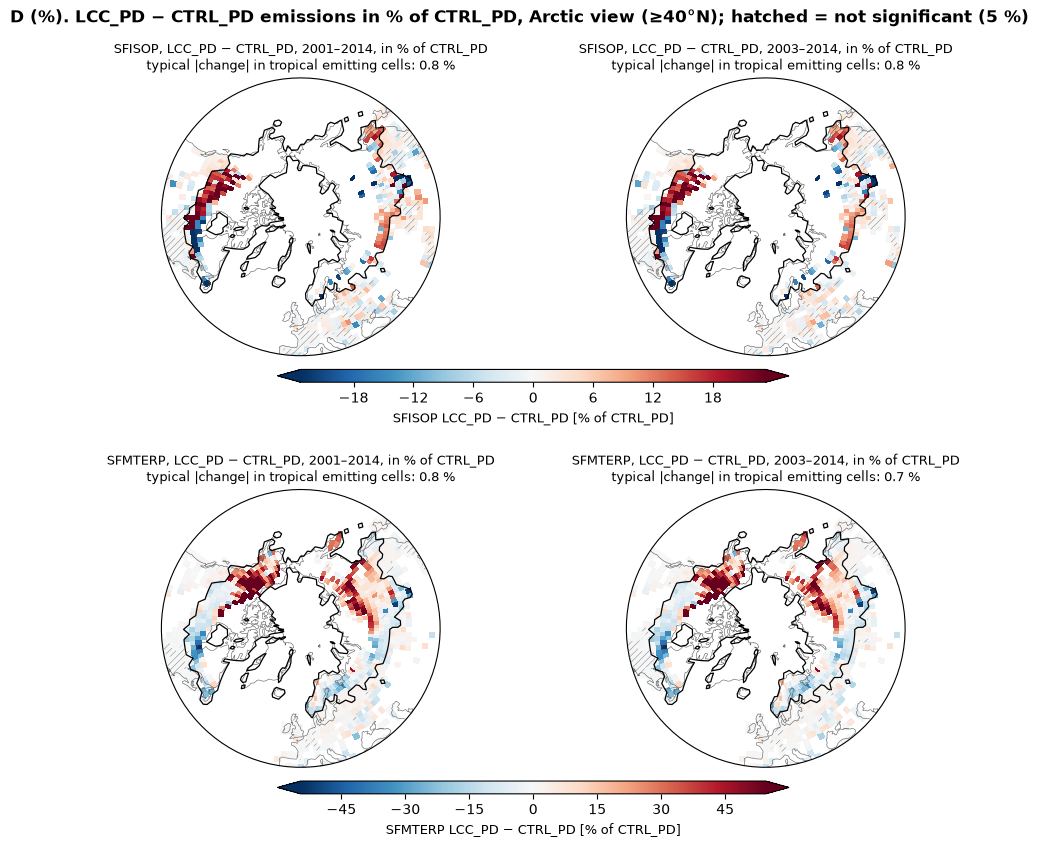

In [23]:
def sig_maps_pct(arctic):
    periods = ['2001–2014', '2003–2014']
    proj, h = (ccrs.NorthPolarStereo(), 4.9) if arctic else (ccrs.Robinson(), 3.9)
    fig, axes = plt.subplots(2, 2, figsize=(11, 2 * h), subplot_kw=dict(projection=proj))
    for row, var in zip(axes, ('SFISOP', 'SFMTERP')):
        c = yearly_atm('CTRL_PD', 'BVOC', var)
        pct = {p: (100 * EMS[var][p][0] / c.sel(year=slice(int(p[:4]), int(p[-4:]))).mean('year')).where(EMITS[var])
               for p in periods}
        vmax = max(fm.symmetric_vmax(v, q=0.98) for v in pct.values())   # same scale for global and Arctic views
        for ax, p in zip(row, periods):
            sig = EMS[var][p][2]
            area_sel = (W['lat'] >= 45) if arctic else xr.ones_like(W, dtype=bool)
            trop = (abs(W['lat']) <= 30) & EMITS[var]
            typ = float(area_mean(abs(pct[p]), trop))
            pm = global_map(ax, pct[p], vmax, f'{var}, LCC_PD − CTRL_PD, {p}, in % of CTRL_PD\n'
                            f'typical |change| in tropical emitting cells: {typ:.1f} %', arctic=arctic)
            fm.add_stippling(ax, EMITS[var] & ~sig, style='lines', zorder=4)
        cb = plt.colorbar(pm, ax=list(row), orientation='horizontal', shrink=0.6, pad=0.04, aspect=40, extend='both')
        cb.locator = MaxNLocator(nbins=9, symmetric=True); cb.update_ticks()
        cb.set_label(f'{var} LCC_PD − CTRL_PD [% of CTRL_PD]', fontsize=9)
    view = 'Arctic view (≥40°N)' if arctic else 'global'
    fig.suptitle(f'D (%). LCC_PD − CTRL_PD emissions in % of CTRL_PD, {view}; hatched = not significant (5 %)',
                 fontweight='bold', y=0.97 if not arctic else 0.95)
    fig.savefig(OUT / 'figures' / f'map_lcc_minus_ctrl_emission_significance_pct{"_arctic" if arctic else ""}.png',
                dpi=200, bbox_inches='tight')

if READY:
    sig_maps_pct(False)
    sig_maps_pct(True)
else:
    print('pending')

### Reading 4e
These numbers are from the run of 2026-11-03. They don't change with the comparison years, because this section uses the interactive runs over 2001–2014. Marked cells are counted among emitting cells only (see above).

| Region | Isoprene: marked cells / share of \|D\| in them | Monoterpene: marked / share of \|D\| | Net isoprene LCC − CTRL, 2001–14 → 2003–14 [Tg yr⁻¹] |
|---|---|---|---|
| LCC cells | 84 % / 70 % | 89 % / 90 % | +0.24 → +0.23 |
| other ≥45°N | 33–38 % / 53–57 % | 60–63 % / 81–84 % | +0.05 → +0.04 |
| <45°N | 12–13 % / 22–27 % | 20 % / 34 % | **−0.74 → +0.08** |

- **South of 45°N.** The net 2001–2014 isoprene difference (−0.74 Tg yr⁻¹, of ~510 Tg yr⁻¹ globally) is almost all the 2001–2002 offset: it is +0.08 Tg yr⁻¹ for 2003–2014. Locally the differences are large (sum of |D| 2.6–2.8 Tg yr⁻¹, 4× the LCC cells) and scattered with both signs. About three quarters of that |D| sits in cells that are not significant: mostly unforced noise. MEGAN responds to temperature, light and soil moisture, which nudging (winds and pressure only) does not fix. The marked tropical cells (12–20 %, noise level 5 %) point to a smaller, persistent part: the prognostic vegetation of the two runs slowly diverges cell by cell (b; leaf area south of 45°N is still −0.09 % in 2003–2014, section 4c). Neither is caused by the land-cover change.
- **Other cells ≥45°N.** 33–63 % of the emitting cells are marked, holding 53–84 % of |D|. This is a real response next to the LCC cells, to the changed climate around the new forest, and it belongs to the forest-expansion effect.
- **For design A.** BVOC_A's emission change = LCC cells (wanted) + neighbour response (wanted) + tropical noise, vegetation divergence and the 2001–2002 offset (unwanted). Means ≥45°N or over the LCC cells (3b, 3c) hardly feel the unwanted parts; global means and tropical maps do. A hybrid climatology (LCC_PD north of 45°N, CTRL_PD south) would remove them, but needs a new emission file and a new run.

## 4f. Where do the LCC_PD − CTRL_PD differences come from?
Figure D shows large-looking differences in two places. This section checks what drives each, with the interactive runs, 2001–2014 (yearly means weighted by month length).

**Tropics (|lat| ≤ 30°, emitting cells).** The land cover is identical there (the surfdata differ only at 46–82°N). For each variable: area-weighted mean change and typical |change| in % of CTRL_PD, the share of cells with |t| above the 5 % critical value (as in 4e), and CTRL_PD's year-to-year variability (median over cells). Candidate drivers are the inputs of MEGAN: leaf area (TLAI), vegetation temperature (TV), sunlight (FSDS) and soil moisture (BTRANMN, SOILWATER_10CM), plus vegetation carbon (TOTVEGC) for slow drift. The spatial correlation of the isoprene change with each driver's change says which one the pattern follows.

**North of 45°N.** For the cells where the emission change is significant, split by sign: the mean change of each plant type (PCT_NAT_PFT, LCC_PD − CTRL_PD, % of the natural vegetation) and the median emission change.

**Caveat.** As in 4e the years are treated as independent; for slow pools (TOTVEGC) the share of significant cells is too high (b).

Tropical emitting cells (|lat| ≤ 30°): 1000; years 2001–2014


,what,mean change [% of CTRL],typical |change| [% of CTRL],cells |t| > crit [%] (5 % = noise),"CTRL year-to-year std [% of CTRL, median]",spatial corr with isoprene change
variable,,,,,,
SFISOP,isoprene emission,-0.05,0.82,10.1,5.83,NaN
SFMTERP,monoterpene emission,-0.02,0.81,14.5,4.48,0.88
TLAI,leaf area index,-0.12,1.25,21.5,5.33,0.56
TOTVEGC,vegetation carbon,-0.21,1.13,75.5,0.89,0.06
TV,vegetation temperature,0.00,0.01,7.7,0.08,-0.23
FSDS,downward solar at surface,0.00,0.18,4.0,2.32,0.13
BTRANMN,soil-moisture stress factor,0.03,0.15,8.2,1.13,-0.09
SOILWATER_10CM,soil water 0–10 cm,-0.00,0.29,9.8,3.67,0.07


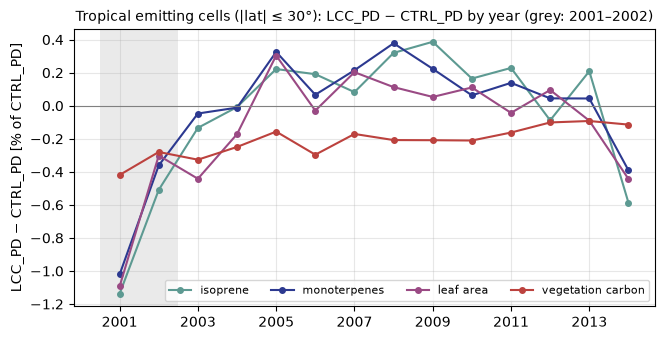

year,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014
SFISOP,-1.14,-0.51,-0.13,-0.01,0.22,0.19,0.08,0.32,0.39,0.16,0.23,-0.09,0.21,-0.59
SFMTERP,-1.02,-0.36,-0.05,-0.01,0.33,0.07,0.21,0.38,0.22,0.06,0.14,0.04,0.04,-0.39
TLAI,-1.09,-0.30,-0.44,-0.17,0.30,-0.03,0.20,0.11,0.05,0.11,-0.04,0.10,-0.09,-0.44
TOTVEGC,-0.42,-0.28,-0.33,-0.25,-0.16,-0.30,-0.17,-0.21,-0.21,-0.21,-0.16,-0.10,-0.09,-0.11


cells  mean lat [°N]  median change [% of CTRL]  of which LCC cells [%]  \
variable sign                                                                            
SFISOP   up      172           54.5                        9.7                    65.7   
         down     87           54.7                       -7.3                    71.3   
SFMTERP  up      390           59.7                        8.7                    71.8   
         down    253           56.1                       -7.4                    79.8   

                                                                                                      largest plant-type changes [% of cell]  
variable sign                                                                                                                                 
SFISOP   up                               broadleaf deciduous boreal +8.3, needleleaf evergreen boreal -5.8, C3 arctic grass -1.8, bare -0.5  
         down      broadleaf deciduous boreal +9.1, needleleaf evergreen boreal -8.3, C3 arctic grass -3.9, needleleaf deciduous boreal +2.3  
SFMTERP  up       C3 arctic grass -11.8, needleleaf deciduous boreal +5.5, needleleaf evergreen boreal +5.2, broadleaf deciduous boreal +2.6  
         down  broadleaf deciduous boreal +10.2, needleleaf evergreen boreal -10.1, broadleaf deciduous temperate +2.1, C3 arctic grass -1.2

In [24]:
PFT_NAMES = ['bare', 'needleleaf evergreen temperate', 'needleleaf evergreen boreal', 'needleleaf deciduous boreal',
             'broadleaf evergreen tropical', 'broadleaf evergreen temperate', 'broadleaf deciduous tropical',
             'broadleaf deciduous temperate', 'broadleaf deciduous boreal', 'broadleaf evergreen shrub temperate',
             'broadleaf deciduous shrub temperate', 'broadleaf deciduous shrub boreal', 'C3 arctic grass', 'C3 grass',
             'C4 grass']   # CLM natpft order

def yearly_lnd(alias, cls, var):
    # yearly means 2001–2014 of a land field, on the atmosphere grid coordinates (same grid, float labels differ)
    f = sorted(PROC.glob(f'{alias}_lnd_{cls}_*-*.nc'))[0]
    ds = xr.open_dataset(f)
    y = fm.annual_mean(ds[var], ds).load()
    assert np.allclose(y['lat'], W['lat'], atol=1e-3) and np.allclose(y['lon'], W['lon'], atol=1e-3)
    return y.assign_coords(lat=W['lat'].values, lon=W['lon'].values)

DRIVERS = {'SFISOP': ('atm', 'BVOC', 'isoprene emission'), 'SFMTERP': ('atm', 'BVOC', 'monoterpene emission'),
           'TLAI': ('lnd', 'LAND', 'leaf area index'), 'TOTVEGC': ('lnd', 'BIOGEOCHEM', 'vegetation carbon'),
           'TV': ('lnd', 'LAND', 'vegetation temperature'), 'FSDS': ('lnd', 'ENERGY', 'downward solar at surface'),
           'BTRANMN': ('lnd', 'HYDRO', 'soil-moisture stress factor'), 'SOILWATER_10CM': ('lnd', 'LAND', 'soil water 0–10 cm')}

if READY:
    YC, YL = {}, {}
    for v, (comp, cls, _) in DRIVERS.items():
        get = yearly_atm if comp == 'atm' else yearly_lnd
        YC[v], YL[v] = get('CTRL_PD', cls, v), get('LCC_PD', cls, v)
    TROP = (abs(W['lat']) <= 30) & EMITS['SFISOP']
    n = YC['SFISOP'].sizes['year']; tcrit = stats.t.ppf(0.975, n - 1)
    pctD = {}
    rows = []
    for v, (_, _, desc) in DRIVERS.items():
        d = YL[v] - YC[v]; cm = YC[v].mean('year')
        D = d.mean('year'); t = D / (d.std('year', ddof=1) / np.sqrt(n))
        pctD[v] = (100 * D / abs(cm)).where(TROP)
        iav = (100 * YC[v].std('year', ddof=1) / abs(cm)).where(TROP)
        rows.append({'variable': v, 'what': desc,
                     'mean change [% of CTRL]': float(area_mean(pctD[v], TROP)),
                     'typical |change| [% of CTRL]': float(area_mean(abs(pctD[v]), TROP)),
                     'cells |t| > crit [%] (5 % = noise)': 100 * float((abs(t) > tcrit).where(TROP).mean()),
                     'CTRL year-to-year std [% of CTRL, median]': float(iav.median()),
                     'spatial corr with isoprene change': np.nan if v == 'SFISOP' else float(xr.corr(pctD['SFISOP'], pctD[v]))})
    TROP_TAB = pd.DataFrame(rows).set_index('variable')
    TROP_TAB.round(3).to_csv(OUT / 'tables' / 'lcc_minus_ctrl_tropics_drivers.csv')
    print(f'Tropical emitting cells (|lat| ≤ 30°): {int(TROP.sum())}; years {int(YC["SFISOP"].year[0])}–{int(YC["SFISOP"].year[-1])}')
    display(TROP_TAB.round(2))

    # year by year: tropical means in % of CTRL_PD's 2001–2014 mean
    YR = pd.DataFrame({v: [float(area_mean((100 * (YL[v] - YC[v]).sel(year=y) / abs(YC[v].mean('year'))).where(TROP), TROP))
                           for y in YC[v]['year'].values] for v in ('SFISOP', 'SFMTERP', 'TLAI', 'TOTVEGC')},
                      index=YC['SFISOP']['year'].values)
    YR.index.name = 'year'
    YR.round(3).to_csv(OUT / 'tables' / 'lcc_minus_ctrl_tropics_by_year.csv')
    fig, ax = plt.subplots(figsize=(7.5, 3.6))
    for (v, lab), col in zip([('SFISOP', 'isoprene'), ('SFMTERP', 'monoterpenes'), ('TLAI', 'leaf area'),
                              ('TOTVEGC', 'vegetation carbon')], ['#5D9A92', '#2C3990', '#9A4A84', '#BC423E']):
        ax.plot(YR.index, YR[v], marker='o', ms=4, color=col, label=lab)
    ax.axhline(0, color='0.5', lw=0.8); ax.axvspan(2000.5, 2002.5, color='#CCCCCC', alpha=0.4, lw=0)
    ax.set_ylabel('LCC_PD − CTRL_PD [% of CTRL_PD]'); ax.set_xticks(YR.index[::2])
    ax.set_title('Tropical emitting cells (|lat| ≤ 30°): LCC_PD − CTRL_PD by year (grey: 2001–2002)', fontsize=10)
    ax.legend(fontsize=8, ncol=4, loc='lower right'); ax.grid(alpha=0.3)
    fig.savefig(OUT / 'figures' / 'lcc_minus_ctrl_tropics_by_year.png', dpi=200, bbox_inches='tight')
    plt.show()
    display(YR.round(2).T)

    # north of 45°N: plant-type change behind the significant up/down cells
    pft = (yearly_lnd('LCC_PD', 'LAND', 'PCT_NAT_PFT') - yearly_lnd('CTRL_PD', 'LAND', 'PCT_NAT_PFT')).isel(year=0)
    rows = []
    for var in ('SFISOP', 'SFMTERP'):
        D, t, sig = EMS[var]['2001–2014']
        cm = yearly_atm('CTRL_PD', 'BVOC', var).mean('year')
        for lab, m in {'up': sig & (D > 0), 'down': sig & (D < 0)}.items():
            m = m & (W['lat'] >= 45)
            ch = pft.where(m).mean(('lat', 'lon'))
            top = sorted(zip(ch.values, PFT_NAMES), key=lambda x: -abs(x[0]))[:4]
            rows.append({'variable': var, 'sign': lab, 'cells': int(m.sum()),
                         'mean lat [°N]': float(W['lat'].where(m).mean()),
                         'median change [% of CTRL]': float((100 * D / cm).where(m).median()),
                         'of which LCC cells [%]': 100 * float(LCCM.where(m).sum() / m.sum()),
                         'largest plant-type changes [% of cell]': ', '.join(f'{nm} {v:+.1f}' for v, nm in top)})
    NORTH_TAB = pd.DataFrame(rows).set_index(['variable', 'sign'])
    NORTH_TAB.round(2).to_csv(OUT / 'tables' / 'lcc_minus_ctrl_north_pft_drivers.csv')
    with pd.option_context('display.max_colwidth', 200):
        display(NORTH_TAB.round(1))
else:
    print('pending')

### Reading 4f
Numbers from the run of 2026-11-04 (interactive runs, 2001–2014; they do not depend on the comparison years). They change only if LCC_PD or CTRL_PD are rerun.

**Figure D in %.** Over the LCC cells the changes are tens of % (isoprene up to ~±20 %, monoterpenes up to ~±50 %); in the tropical emitting cells the typical |change| is **0.7–0.8 %**, pale and mostly hatched. The dark tropical pixels of Figure D come from the absolute scale (tropical isoprene ~15 mg m⁻² day⁻¹), not from large changes.

**Tropics (|lat| ≤ 30°, emitting cells), `lcc_minus_ctrl_tropics_drivers.csv`:**

| | mean change | typical \|change\| | cells \|t\| > crit (5 % = noise) | CTRL year-to-year std | corr. with isoprene change |
|---|---|---|---|---|---|
| isoprene | −0.05 % | 0.82 % | 10 % | 5.8 % | – |
| monoterpenes | −0.02 % | 0.81 % | 15 % | 4.5 % | +0.88 |
| leaf area (TLAI) | −0.12 % | 1.25 % | 22 % | 5.3 % | **+0.56** |
| vegetation carbon | −0.21 % | 1.13 % | 76 % (b, slow pool) | 0.9 % | +0.06 |
| vegetation temperature | +0.00 % | 0.01 % | 8 % | 0.08 % | −0.23 |
| sunlight (FSDS) | +0.01 % | 0.18 % | 4 % | 2.3 % | +0.13 |
| soil moisture (BTRANMN / 0–10 cm) | +0.03 / −0.00 % | 0.15 / 0.29 % | 8 / 10 % | 1.1 / 3.7 % | −0.09 / +0.07 |

- The changes are **~7× smaller than the year-to-year variability** of CTRL_PD itself, and only slightly more cells pass the test than noise would give (10–15 % vs 5 %).
- The pattern follows **leaf area** (r = +0.56), not temperature, light or soil moisture, which hardly differ. So the tropical part is the vegetation of the two runs, not the weather.
- **By year** (`lcc_minus_ctrl_tropics_by_year.csv`, figure): isoprene −1.14 % (2001) and −0.51 % (2002), then within ±0.4 % to 2014 (2014: −0.59 %); leaf area follows the same course. The two runs start from **different land restarts** (each from its own spin-up) and need ~2 years to converge, hence the 2003–2014 column in 4e. Vegetation carbon stays ~0.1–0.4 % lower throughout: a small, slow leftover of the different spin-ups (b).

**North of 45°N, significant cells, 2001–2014** (`lcc_minus_ctrl_north_pft_drivers.csv`; 66–80 % of these cells are LCC cells):

| | cells | median change | largest plant-type changes [% of cell] |
|---|---|---|---|
| monoterpenes up | 390 (~60°N) | +8.7 % | arctic C3 grass −11.8, needleleaf deciduous boreal +5.5, needleleaf evergreen boreal +5.2 |
| monoterpenes down | 253 (~56°N) | −7.4 % | broadleaf deciduous boreal +10.2, needleleaf evergreen boreal −10.1 |
| isoprene up | 172 (~54°N) | +9.7 % | broadleaf deciduous boreal +8.3, needleleaf evergreen boreal −5.8 |
| isoprene down | 87 (~55°N) | −7.3 % | broadleaf deciduous boreal +9.1, needleleaf evergreen boreal −8.3, arctic grass −3.9 |

- **Monoterpenes follow the plant types:** needleleaf trees on former tundra → up (northern band); broadleaf replacing needleleaf → down (southern band).
- **Isoprene does not:** up and down cells have the same plant-type swap (broadleaf deciduous boreal in, needleleaf evergreen out). Its sign must come from something else, e.g. the per-PFT emission factors at those cells, leaf area or the local climate response (c, not tested here).

**Bottom line.** North of 45°N the LCC − CTRL emission differences are the land-cover effect (wanted). In the tropics they are small (<1 %), follow leaf area, and come mostly from the first two years after the start from different land restarts (unwanted, but small; see 4e "For design A").

## 5. What next
- **Design B adequate** → keep the matched baseline everywhere: PD BVOC = C − art_CTRL; FUT BVOC = (LCC_FUT − LCC_FUT_fBVOC*) − art_FUT, with art_FUT = CTRL_FUT − CTRL_FUT_fBVOCctrlFUT (script 24e, auto-launched with LCC_FUT_fBVOCctrlFUT).
- **Artefact depends on the land** → design A in FUT: rerun LCC_FUT with `cam_diagnostics HR_BVOC_ALL`, build its climatology, run LCC_FUT_fBVOClccFUT (needs the user's OK).
- **In between** → extend LCC_PD_fBVOClccPD by a few years (it restarts from 2003-01-01) to reduce the noise.